# 22 · Zaman Serisi Tahmini (ARIMA/SARIMA, ETS ve Makine Öğrenmesi ile Forecasting)

> **Bu notebook'ta ne öğreneceğiz?**
> Şimdiye kadar gözlemleri **birbirinden bağımsız** varsaydık (satırları karıştırıp CV yaptık). Zaman serisinde bu varsayım çöker: **bugün dünün devamıdır**, sıra bilgidir ve gelecek, geçmişi kullanarak
> tahmin edilir. Bu notebook'ta iki dünyayı karşılaştıracağız ve **sıfırdan yazıp** kütüphanelerle doğrulayacağız:
>
> 1. **Klasik istatistiksel modeller:** durağanlık, ACF/PACF, farklama, **AR(p)** (OLS ve Yule–Walker), **SES/ETS** ve **ARIMA(0,1,1) ≡ SES** denkliği, **SARIMA**, AICc ile model seçimi, Ljung–Box tanısı.
> 2. **Doğru değerlendirme:** **MASE**, **rolling-origin (yürüyen başlangıç)** değerlendirmesi, mevsimsel naif taban çizgisi; tek bir hold-out'un neden yanıltıcı olduğu.
> 3. **ML ile forecasting:** seriyi tabloya çevirme (gecikme/lag, yuvarlanan pencere, takvim, **Fourier** öznitelikleri), **direct vs recursive** çok adımlı tahmin, Ridge ve LightGBM; ağaçların **trendi neden ekstrapole edemediği**.
> 4. **Sızıntı (leakage) ve belirsizlik:** `rolling(center=True)` gibi sinsi hatalar, karıştırılmış CV vs `TimeSeriesSplit`, **quantile regresyon** ve **conformal** tahmin aralıkları, kapsama (coverage) testi.
>
> **Önkoşul:** 02/04 · Regresyon & Ridge, 08-09 · Ağaç topluluğu ve gradient boosting, 10-13 · CV/değerlendirme, 21 · Belirsizlik ve kalibrasyon (kapsama fikri).
>
> **Veri (hepsi serinin önceki notebook'larında kullanılmadı):**
> - `wineind` — Avustralya'da aylık şarap satışları (Ocak 1980 – Ağustos 1994, 176 ay; `forecast` paketi/ABS): güçlü yıllık mevsimsellik, klasik SARIMA/ETS örneği.
> - `us_gasoline` — ABD haftalık benzin tedariki (milyon varil/gün; Şubat 1991 – Ocak 2017, 1.355 hafta; EIA): **52,18 haftalık kesirli mevsimsellik** (klasik SARIMA'nın zorlandığı durum) ve değişen trend.
> - `Melbourne günlük minimum sıcaklık` — 1981–1990, 3.650 gün (Avustralya Meteoroloji Bürosu): uzun, gürültülü günlük seri; sızıntı ve aralık deneyleri.
>
> **Araçlar:** `numpy`/`scipy` (sıfırdan), `statsmodels` (ETS, SARIMAX, testler), `sklearn` (Ridge, `TimeSeriesSplit`), `lightgbm`; R (`forecast`), DuckDB (SQL pencere fonksiyonları).

## 1 · Zaman Serisinin Anatomisi ve Durağanlık

Bir seri $y_t$ çoğu zaman şu bileşenlerin toplamı (veya çarpımı) olarak düşünülür:
$$y_t = T_t + S_t + R_t\quad(\text{toplamsal}),\qquad y_t = T_t\cdot S_t\cdot R_t\quad(\text{çarpımsal; log alınca toplamsal olur}),$$
$T$ trend, $S$ periyodu $m$ olan mevsimsellik ($m=12$ aylık, $m\approx52$ haftalık, $m=7$ günlük-haftalık), $R$ artık. **STL** bu ayrıştırmayı yerel regresyonla yapar.

**Zayıf durağanlık:** $\mathbb{E}[y_t]$ sabit, $\mathrm{Var}(y_t)$ sabit ve $\mathrm{Cov}(y_t,y_{t+k})$ yalnızca $k$'ya bağlı. ARMA ailesi durağan seri ister; trend/mevsimsellik **farklama** ile giderilir:
$$\nabla y_t = y_t-y_{t-1},\qquad \nabla_m y_t = y_t-y_{t-m}.$$
**Testler:** ADF ($H_0$: birim kök var → durağan *değil*; küçük $p$ durağan demektir) ve KPSS ($H_0$: durağan; küçük $p$ durağan *değil* demektir). İkisi **zıt** hipotez kurar, birlikte okunur.

**ACF / PACF:** $\rho_k=\mathrm{Corr}(y_t,y_{t-k})$; PACF, aradaki gecikmelerin etkisi çıkarılmış korelasyondur. Okuma kuralı: **AR(p)** → PACF $p$'den sonra kesilir, ACF üstel söner; **MA(q)** → ACF $q$'dan sonra kesilir; mevsimsel gecikmelerde ($m,2m,\dots$) çıkan çıkıntılar mevsimsel terimleri işaret eder.

### 🔍 Somut örnek — AR(1): OLS ve Yule–Walker aynı şeyi mi veriyor?
Seri $y=(1,2,4,3,5)$, ortalama $3$, ortalanmış $c=(-2,-1,1,0,2)$. AR(1): $c_t=\phi\,c_{t-1}+\varepsilon_t$.

- **OLS:** $x=c_{1..4}\!\to\!(-2,-1,1,0)$, hedef $(-1,1,0,2)$ ⇒ $\hat\phi=\dfrac{\sum x\,t}{\sum x^2}=\dfrac{2-1+0+0}{4+1+1+0}=\dfrac{1}{6}\approx0{,}167$.
- **Yule–Walker:** $\hat\phi=r_1=\dfrac{\sum_{t}c_{t-1}c_t}{\sum_t c_t^2}=\dfrac{1}{10}=0{,}10$ (payda **beş** terimin karesi: $4+1+1+0+4$).
- Fark küçük örneklemde kenar etkisinden gelir (paydada bir terim fazla); $n$ büyüdükçe kapanır.
- **Tahmin:** son ortalanmış değer $2$ ⇒ 1 adım: $3+\tfrac16\cdot2=3{,}33$; 2 adım: $3+\tfrac1{36}\cdot2=3{,}06$ — tahmin **ortalamaya geri döner** (durağan modelin imzası). Birim köklü (rastgele yürüyüş) modelde bu olmaz, tahmin düz kalır ve belirsizlik $\sqrt h$ ile büyür.

## 2 · ARIMA, SARIMA ve Üstel Düzleştirme (ETS)

Geri kaydırma operatörü $B y_t=y_{t-1}$ ile **ARIMA(p,d,q)**:
$$\phi(B)\,(1-B)^d\,y_t=c+\theta(B)\,\varepsilon_t,\quad \phi(B)=1-\phi_1B-\dots-\phi_pB^p,\ \ \theta(B)=1+\theta_1B+\dots+\theta_qB^q .$$
**SARIMA(p,d,q)(P,D,Q)$_m$**, çarpımsal mevsimsel polinomlar ekler: $\Phi(B^m)\phi(B)(1-B)^d(1-B^m)^D y_t=\Theta(B^m)\theta(B)\varepsilon_t$. Mertebe seçimi **AICc** ($\text{AIC}+\frac{2k(k+1)}{n-k-1}$) ile; aynı **dönüşüm ve farklama** derecesindeki modeller karşılaştırılabilir (log'lu ve log'suz serinin AIC'leri kıyaslanamaz).

**Basit üstel düzleştirme (SES):** seviye $\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1}$, tahmin $\hat y_{t+h}=\ell_t$ (düz). Holt trend, Holt–Winters mevsimsellik ekler (ETS: Hata–Trend–Mevsim bileşenleri toplamsal/çarpımsal).

### 🔍 Somut örnek — SES elle ($\alpha=0{,}5$, $\ell_0=y_0$)
$y=(10,12,11,13)$: $\ell_1=0{,}5\cdot12+0{,}5\cdot10=11$; $\ell_2=0{,}5\cdot11+0{,}5\cdot11=11$; $\ell_3=0{,}5\cdot13+0{,}5\cdot11=\mathbf{12}$ ⇒ tüm gelecek için $\hat y=12$. Bir adım ileri hatalar: $12-10=2,\ 11-11=0,\ 13-11=2$ ⇒ $\text{SSE}=8$; $\alpha$ bu SSE'yi minimize edecek şekilde seçilir.

**Denklik:** SES ≡ **ARIMA(0,1,1)** ($\theta_1=\alpha-1$). Yani ETS ile ARIMA ayrı dünyalar değil, kesişen aileler; bunu aşağıda sayısal olarak göstereceğiz.

## 3 · Doğru Ölçü, Doğru Değerlendirme

Ölçekten bağımsız ve sıfıra bölünmeyen ölçü: **MASE** (Hyndman & Koehler 2006),
$$\text{MASE}=\frac{\tfrac1H\sum_{h=1}^{H}|y_{T+h}-\hat y_{T+h}|}{\tfrac1{T-m}\sum_{t=m+1}^{T}|y_t-y_{t-m}|}.$$
Payda, **eğitim kümesindeki mevsimsel naif tahminin** MAE'sidir; MASE $<1$ ⇒ "mevsimsel naiften iyi". ($m=1$ ise naif.)

### 🔍 Somut örnek — MASE elle
Eğitim $(10,20,12,22,14,24)$, $m=2$: mevsimsel naif hataları $|12-10|,|22-20|,|14-12|,|24-22|=2$ ⇒ payda $=2$. Test gerçek $(16,26)$. Tahmin $(14,24)$: MAE $=2$ ⇒ **MASE $=1{,}0$**; tahmin $(15,25)$: MAE $=1$ ⇒ **MASE $=0{,}5$**.

**Rolling-origin (zaman serisi çapraz doğrulaması):** tek bir bölme yerine, başlangıç noktasını ileri kaydır: her $T_i$ için $y_{1..T_i}$ ile eğit, $y_{T_i+1..T_i+H}$'yi tahmin et, hataları **tüm başlangıçlar ve ufuklar** üzerinde ortala. Tek bir son-24-ay testi, o 24 ayın şansına/kaprisine bağlıdır; birçok başlangıç belirsizliği (std) de verir. Satırları **karıştırmak** geleceği eğitime sokar.

## 4 · ML ile Forecasting: Seriyi Tabloya Çevirmek

Hedef $y_{t+h}$; öznitelikler yalnızca **$t$ anında bilinen** şeyler:

- **Gecikmeler** $y_t,y_{t-1},\dots$ ve **mevsimsel gecikme** $y_{t+h-m}$ (hedef tarihine denk gelen geçen yıl/hafta); 
- **Yuvarlanan istatistikler** — dikkat: önce `shift(1)`, sonra `rolling` (aksi halde pencere hedefi içerir!); `rolling(center=True)` **kesin sızıntıdır**;
- **Takvim / Fourier:** $\sin\!\big(2\pi k\,t/P\big),\cos\!\big(2\pi k\,t/P\big)$, $k=1..K$ ($P$ kesirli olabilir: 52,18). Mevsimsel dummy'den çok daha az parametreyle esnek mevsimsellik; **dynamic harmonic regression** = Fourier regresörleri + ARIMA hataları.

**Çok adımlı stratejiler:** *Recursive* — tek bir 1-adım modeli, tahminini kendine girdi yapar (hata birikir). *Direct* — her ufuk $h$ için ayrı model $y_{t+h}=f_h(\text{özellikler}_t)$ (hata birikmez, $H$ model gerekir). *MIMO / global* — tek model, $h$ bir öznitelik.

**Ağaçlar ekstrapole edemez:** karar ağacı/RF/GBM tahminlerini eğitimde görülen hedef aralığına hapseder (yaprak ortalamaları). Trendli seride seviyeyi doğrudan tahmin etmek yerine **farkı** ($y_{t+h}-y_t$) veya trend-çıkarılmış hedefi tahmin et, ya da trendi doğrusal bir bileşenle (Ridge/Fourier+trend) modelle. Aşağıda sentetik seride bunu göreceğiz.

**Belirsizlik:** (i) model-tabanlı aralık (ARIMA/ETS, hataların Gauss olduğunu varsayar), (ii) **quantile regresyon** (pinball kayıp, LightGBM `objective='quantile'`), (iii) **conformal:** ayrı bir kalibrasyon kümesinde mutlak artıkların $\lceil(1-\alpha)(n+1)\rceil$. en küçüğü $\hat q$; aralık $\hat y\pm\hat q$. İkincisi ve üçüncüsü dağılım varsayımı istemez ama **değiş-tokuşabilirlik** (zaman serisinde yalnızca yaklaşık) ister ⇒ kapsama her zaman **zaman-sıralı bir test kümesinde ölçülmelidir**.

## 5 · Ne Zaman Hangisi? (Özet)

| Durum | İlk tercih | Neden |
|---|---|---|
| Tek, kısa/orta seri, net mevsimsellik, açıklanabilirlik | ETS / SARIMA | Az veri ile iyi; tanı ve aralık hazır |
| Kesirli mevsimsellik (haftalık, yarım saatlik) | Fourier + ARIMA hatası veya ML | SARIMA $m=52$ hantal ve yaklaşık |
| Çok sayıda seri / dış değişken (promosyon, hava) / karmaşık etkileşim | LightGBM (direct/global) + lag/takvim | Dış regresörleri doğal alır |
| Güçlü trend + ağaç modeli | Farkı/trend-çıkarılmışı hedefle veya doğrusal trend ekle | Ağaç ekstrapole edemez |
| Her zaman | Mevsimsel naif + MASE + rolling-origin | Taban çizgisi yenilemiyorsa karmaşıklığın değeri yoktur |

# 🐍 Python Uygulaması

Adımlar:
1. **wineind keşfi:** STL ayrıştırması, mevsimsellik/trend gücü, ADF–KPSS ile farklama kararı, ACF/PACF
2. **Sıfırdan:** AR(p) (OLS ve Yule–Walker), SES, MASE; `statsmodels` ile doğrulama ve **ARIMA(0,1,1) ≡ SES**
3. **Klasik modeller, yürüyen başlangıçla:** mevsimsel naif, ETS, SARIMA — MASE, belirsizlik ve Ljung–Box
4. **Haftalık benzin (kesirli mevsimsellik):** Fourier + ARIMA, Ridge, LightGBM (direct/recursive) — 4 ufukta karşılaştırma
5. **Ağaçlar ve trend:** sentetik ekstrapolasyon deneyi
6. **Melbourne sıcaklığı:** sızıntı (leakage) deneyleri, quantile ve conformal aralıklar, kapsama

In [1]:
import warnings
import time
import datetime as dt
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize

from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.regression.linear_model import yule_walker
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit
import lightgbm as lgb

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (11, 4.5)

def quiet(fn, *a, **k):
    """Uyarıları gizlemeden YAKALAR ve sayar: (sonuç, uyarı sayısı)."""
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter('always'); out = fn(*a, **k)
    return out, len(wl)

def mase(actual, pred, train, m=1):
    """MASE: test MAE / eğitimdeki mevsimsel-naif MAE (m: mevsim uzunluğu)."""
    tr = np.asarray(train, float); scale = np.mean(np.abs(tr[m:] - tr[:-m]))
    return np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float))) / scale

# MASE elle örnek (teori bölümü)
tr_ = [10, 20, 12, 22, 14, 24]; print("MASE elle:", mase([16, 26], [14, 24], tr_, m=2), mase([16, 26], [15, 25], tr_, m=2), "(beklenen 1.0 ve 0.5)")

MASE elle: 1.0 0.5 (beklenen 1.0 ve 0.5)


## Adım 1 · wineind: Ayrıştırma, Durağanlık, ACF/PACF

176 aylık şarap satışı (adet). Önce STL ile trend/mevsim/artık bileşenlerini, ardından **mevsimsellik gücü** $F_S=\max(0,1-\mathrm{Var}(R)/\mathrm{Var}(S+R))$ ve **trend gücü** $F_T=\max(0,1-\mathrm{Var}(R)/\mathrm{Var}(T+R))$ (Wang, Smith, Hyndman 2006) değerlerini hesaplıyoruz.

wineind: 176 ay, 1980-01 → 1994-08 | ort. 25,392 | min 13,652 (1994-01) | maks 40,226 (1987-12)
Ay ortalamaları (1=Oca): {1: 17174, 2: 20366, 3: 23445, 4: 24266, 5: 23595, 6: 23582, 7: 28506, 8: 28104, 9: 24213, 10: 25899, 11: 30890, 12: 35670}
log-seri STL: mevsimsellik gücü F_S=0.897 | trend gücü F_T=0.565 | artık sd (log)=0.063


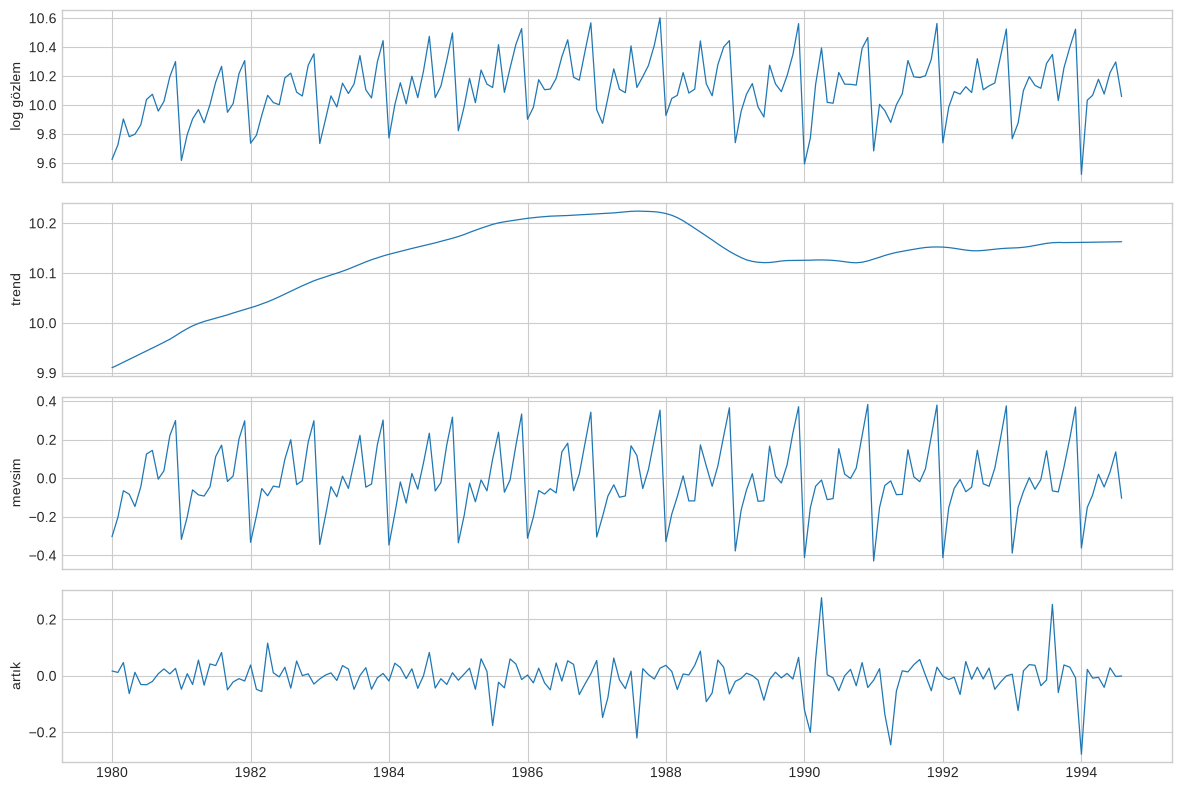

YORUM: Mevsimsellik çok güçlü (F_S=0.90) ve en yüksek satış ayı 12. ay, en düşük 1. ay; trend gücü ise 0.57 — seri trendden çok mevsim ve düzensiz dalgalanmalarla yönetiliyor.


In [2]:
w = pd.read_csv('data/wineind.csv')
wine = pd.Series(w.value.values.astype(float), index=pd.date_range('1980-01-01', periods=len(w), freq='MS'), name='wine')
print(f"wineind: {len(wine)} ay, {wine.index[0]:%Y-%m} → {wine.index[-1]:%Y-%m} | ort. {wine.mean():,.0f} | min {wine.min():,.0f} ({wine.idxmin():%Y-%m}) | maks {wine.max():,.0f} ({wine.idxmax():%Y-%m})")
mon = wine.groupby(wine.index.month).mean(); print("Ay ortalamaları (1=Oca):", mon.round(0).astype(int).to_dict())

stl = STL(np.log(wine), period=12, robust=True).fit()
T_, S_, R_ = stl.trend, stl.seasonal, stl.resid
FS = max(0, 1 - R_.var() / (S_ + R_).var()); FT = max(0, 1 - R_.var() / (T_ + R_).var())
print(f"log-seri STL: mevsimsellik gücü F_S={FS:.3f} | trend gücü F_T={FT:.3f} | artık sd (log)={R_.std():.3f}")
fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for a_, (nm, s_) in zip(ax, [('log gözlem', np.log(wine)), ('trend', T_), ('mevsim', S_), ('artık', R_)]): a_.plot(s_, lw=.9); a_.set_ylabel(nm)
plt.tight_layout(); plt.show()
print(f"YORUM: Mevsimsellik çok güçlü (F_S={FS:.2f}) ve en yüksek satış ayı {int(mon.idxmax())}. ay, en düşük {int(mon.idxmin())}. ay; trend gücü ise {FT:.2f} — seri trendden çok mevsim ve düzensiz dalgalanmalarla yönetiliyor.")

   dönüşüm  ADF_p  KPSS_p  KPSS_uyarı                   sonuç
         y 0.0512    0.01           2 çelişkili/durağan değil
     log y 0.0250    0.01           2 çelişkili/durağan değil
 ∇12 log y 0.1428    0.01           2 çelişkili/durağan değil
   ∇ log y 0.0000    0.10           2                 durağan
∇∇12 log y 0.0000    0.10           2                 durağan
(KPSS p-değeri tablo sınırının dışındaysa statsmodels InterpolationWarning verir; uyarılar yakalanıp 'KPSS_uyarı' sütununda sayıldı. Sınır değerleri 0.01 ve 0.10'dur.)


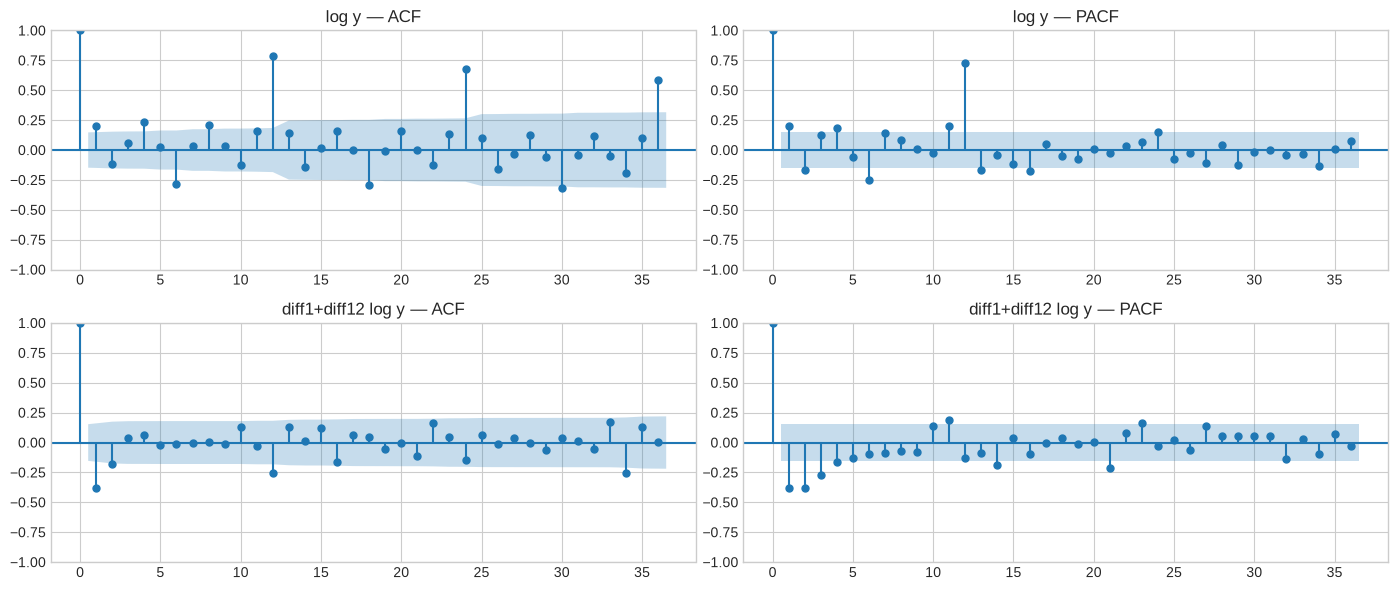

Durağan çıkan dönüşümler: ['∇ log y', '∇∇12 log y']; yalnızca mevsimsel fark (∇12) çelişkili/durağan değil.
ACF(log y): gecikme 12 = 0.79, 24 = 0.68 (yavaş sönüm) | ACF(∇∇12 log y): gecikme 1 = -0.38, 12 = -0.25, 24 = -0.14 (±0.15 sınırı)
YORUM: Tek bir test yetmez: ADF ve KPSS zıt hipotez kurar; tablo hangi dönüşümün ikisini birden geçtiğini gösteriyor. Yalnızca mevsimsel farklama (∇12) seviye kaymalarını gidermediği için yetmiyor; bir de birinci farka ihtiyaç var.
       ∇∇12 serisinde gecikme 1 anlamlı negatif, gecikme 12 anlamlı negatif: MA(1) ve mevsimsel MA(1) terimlerini (airline model (0,1,1)(0,1,1)12) aday yapıyor; Adım 3'te AICc ile sınayacağız.


In [3]:
def stat_tests(s):
    (adf_p, _), nw1 = quiet(lambda: (adfuller(s.dropna(), autolag='AIC')[1], 0))
    (kp_p, _), nw2 = quiet(lambda: (kpss(s.dropna(), regression='c', nlags='auto')[1], 0))
    return adf_p, kp_p, nw2

ly = np.log(wine)
cands = {'y': wine, 'log y': ly, '∇12 log y': ly.diff(12), '∇ log y': ly.diff(), '∇∇12 log y': ly.diff().diff(12)}
rows = []
for k, s in cands.items():
    a_, k_, nw = stat_tests(s); rows.append(dict(dönüşüm=k, ADF_p=a_, KPSS_p=k_, KPSS_uyarı=nw, sonuç=('durağan' if (a_ < .05 and k_ >= .05) else 'çelişkili/durağan değil')))
tab_st = pd.DataFrame(rows); print(tab_st.round(4).to_string(index=False))
print("(KPSS p-değeri tablo sınırının dışındaysa statsmodels InterpolationWarning verir; uyarılar yakalanıp 'KPSS_uyarı' sütununda sayıldı. Sınır değerleri 0.01 ve 0.10'dur.)")

fig, ax = plt.subplots(2, 2, figsize=(14, 6))
plot_acf(ly, lags=36, ax=ax[0, 0], title='log y — ACF'); plot_pacf(ly, lags=36, ax=ax[0, 1], method='ywm', title='log y — PACF')
d2 = ly.diff().diff(12).dropna()
plot_acf(d2, lags=36, ax=ax[1, 0], title='diff1+diff12 log y — ACF'); plot_pacf(d2, lags=36, ax=ax[1, 1], method='ywm', title='diff1+diff12 log y — PACF')
plt.tight_layout(); plt.show()
ac2 = acf(d2, nlags=24); bnd = 1.96 / np.sqrt(len(d2)); ac_l = acf(ly, nlags=24)
ok_ = tab_st.set_index('dönüşüm').sonuç
print(f"Durağan çıkan dönüşümler: {[k for k in ok_.index if ok_[k]=='durağan']}; yalnızca mevsimsel fark (∇12) {ok_['∇12 log y']}.")
print(f"ACF(log y): gecikme 12 = {ac_l[12]:.2f}, 24 = {ac_l[24]:.2f} (yavaş sönüm) | ACF(∇∇12 log y): gecikme 1 = {ac2[1]:.2f}, 12 = {ac2[12]:.2f}, 24 = {ac2[24]:.2f} (±{bnd:.2f} sınırı)")
print("YORUM: Tek bir test yetmez: ADF ve KPSS zıt hipotez kurar; tablo hangi dönüşümün ikisini birden geçtiğini gösteriyor. Yalnızca mevsimsel farklama (∇12) seviye kaymalarını gidermediği için yetmiyor; bir de birinci farka ihtiyaç var.")
neg1 = ac2[1] < -bnd; neg12 = ac2[12] < -bnd
print(f"       ∇∇12 serisinde gecikme 1 {'anlamlı negatif' if neg1 else 'anlamlı değil'}, gecikme 12 {'anlamlı negatif' if neg12 else 'anlamlı değil'}: " + ("MA(1) ve mevsimsel MA(1) terimlerini (airline model (0,1,1)(0,1,1)12) aday yapıyor; Adım 3'te AICc ile sınayacağız." if (neg1 or neg12) else "airline model yine de aday listesine alınacak; AICc karar verecek."))

## Adım 2 · Sıfırdan: AR(p), Yule–Walker, SES ve ARIMA(0,1,1) Denkliği

Teorideki elle örnekleri koda dökeriz: $y=(1,2,4,3,5)$ için OLS $\hat\phi=1/6$, Yule–Walker $0{,}10$, tahmin $3{,}33$ ve $3{,}06$. Ardından `ar_ols` (kesişimli, $p$ gecikme) ve `yule_walker_scratch` (Toeplitz sistemi) yazıp `statsmodels` ile karşılaştırırız. SES için özyinelemeyi ve $\alpha$ eniyilemesini yazıp `SimpleExpSmoothing` ile, son olarak $\theta=\alpha-1$ denkliğini ARIMA(0,1,1) ile sınarız.

In [4]:
# --- AR(1) elle örnek ---
y5 = np.array([1, 2, 4, 3, 5.]); c5 = y5 - y5.mean(); x_, t_ = c5[:-1], c5[1:]
phi_ols = (x_ @ t_) / (x_ @ x_); r1 = (c5[:-1] @ c5[1:]) / (c5 @ c5)
print(f"Elle: phi_OLS={phi_ols:.4f} (1/6={1/6:.4f}) | phi_YW=r1={r1:.4f} | tahmin 1 adım={y5.mean()+phi_ols*c5[-1]:.3f}, 2 adım={y5.mean()+phi_ols**2*c5[-1]:.3f}")

def ar_ols(y, p):
    """AR(p) kesişimli OLS: y_t = c + sum phi_i y_{t-i}. (katsayılar [c, phi_1..phi_p]) döner."""
    y = np.asarray(y, float); X = np.column_stack([np.ones(len(y) - p)] + [y[p - i:len(y) - i] for i in range(1, p + 1)])
    return np.linalg.lstsq(X, y[p:], rcond=None)[0]

def yule_walker_scratch(y, p):
    """Örnek otokovaryanslardan Toeplitz sistemi R phi = r. (phi, sigma2) döner."""
    y = np.asarray(y, float) - np.mean(y); n = len(y)
    g = np.array([y[:n - k] @ y[k:] / n for k in range(p + 1)])
    R = np.array([[g[abs(i - j)] for j in range(p)] for i in range(p)]); phi = np.linalg.solve(R, g[1:])
    return phi, g[0] - phi @ g[1:]

ld = np.log(wine).diff(12).dropna().values            # durağana yakın seri: mevsimsel farklanmış log-şarap
for p in (1, 2, 12):
    b = ar_ols(ld, p); sm_ = AutoReg(ld, lags=p, trend='c').fit().params
    ph, s2 = yule_walker_scratch(ld, p); ph_sm, sg_sm = yule_walker(ld, order=p, method='mle', result_object=False)
    print(f"AR({p:2d}): OLS bizim vs AutoReg maks. fark {np.abs(b - sm_).max():.1e} | YW bizim vs statsmodels maks. fark {np.abs(ph - ph_sm).max():.1e} | sigma2 {s2:.5f} vs {sg_sm**2:.5f}")
print("YORUM: OLS katsayıları AutoReg ile, Yule–Walker katsayıları statsmodels.yule_walker(method='mle') ile makine hassasiyetinde eşleşiyor. OLS ile Yule–Walker aynı sayıyı DEĞİL, birbirine yakın sayıları verir (kenar terimi farkı) — küçük n'de fark büyür, elle örnekte 0.167 vs 0.10.")

Elle: phi_OLS=0.1667 (1/6=0.1667) | phi_YW=r1=0.1000 | tahmin 1 adım=3.333, 2 adım=3.056
AR( 1): OLS bizim vs AutoReg maks. fark 3.5e-18 | YW bizim vs statsmodels maks. fark 0.0e+00 | sigma2 0.01097 vs 0.01097
AR( 2): OLS bizim vs AutoReg maks. fark 2.8e-17 | YW bizim vs statsmodels maks. fark 5.6e-17 | sigma2 0.01088 vs 0.01088
AR(12): OLS bizim vs AutoReg maks. fark 3.3e-16 | YW bizim vs statsmodels maks. fark 6.2e-17 | sigma2 0.00949 vs 0.00949
YORUM: OLS katsayıları AutoReg ile, Yule–Walker katsayıları statsmodels.yule_walker(method='mle') ile makine hassasiyetinde eşleşiyor. OLS ile Yule–Walker aynı sayıyı DEĞİL, birbirine yakın sayıları verir (kenar terimi farkı) — küçük n'de fark büyür, elle örnekte 0.167 vs 0.10.


In [5]:
# --- SES: özyineleme, SSE, alfa eniyilemesi ---
def ses_levels(y, alpha, l0):
    """l_t = alpha*y_t + (1-alpha)*l_{t-1}; döndürür: tüm seviyeler (l_0 dahil)."""
    L = np.empty(len(y) + 1); L[0] = l0
    for t, v in enumerate(y): L[t + 1] = alpha * v + (1 - alpha) * L[t]
    return L

def ses_sse(alpha, y, l0):
    L = ses_levels(y, alpha, l0); return np.sum((np.asarray(y) - L[:-1]) ** 2)           # bir adım ileri tahmin = önceki seviye

yh = np.array([10, 12, 11, 13.]); Lh = ses_levels(yh[1:], 0.5, yh[0])
print(f"SES elle: seviyeler {Lh} -> tahmin {Lh[-1]} | SSE = {ses_sse(0.5, yh[1:], yh[0]):.1f} (beklenen 12 ve 8)")

yl = np.log(wine.values); l0 = yl[0]; ys = yl[1:]
r_ = optimize.minimize_scalar(ses_sse, bounds=(1e-4, 1 - 1e-4), args=(ys, l0), method='bounded', options={'xatol': 1e-10})
m_ses, nw_ses = quiet(lambda: SimpleExpSmoothing(ys, initialization_method='known', initial_level=l0).fit())
print(f"alfa: bizim {r_.x:.5f} | statsmodels {m_ses.params['smoothing_level']:.5f} | SSE bizim {r_.fun:.5f} vs sm {m_ses.sse:.5f} (uyarı {nw_ses})")
print(f"Aynı alfa için tahmin: bizim {ses_levels(ys, r_.x, l0)[-1]:.6f} | statsmodels {m_ses.forecast(1)[0]:.6f}")

# --- SES ≡ ARIMA(0,1,1): aynı parametre (theta = alfa-1) verilince tek-adım tahminler örtüşür ---
a_hat = m_ses.params['smoothing_level']; s2_ = m_ses.sse / len(ys)
ar_free, nw_a = quiet(lambda: SARIMAX(ys, order=(0, 1, 1), trend='n').fit(disp=0))
ar_fix = SARIMAX(ys, order=(0, 1, 1), trend='n').smooth([a_hat - 1, s2_])
L_ses = ses_levels(ys, a_hat, l0)[:-1]                         # SES'in t anındaki bir-adım tahmini
d_ = np.abs(ar_fix.fittedvalues - L_ses)
print(f"theta = alfa-1 = {a_hat-1:.4f} verilince ARIMA(0,1,1) bir-adım tahminleri ile SES: t>=60 için maks. fark {d_[60:].max():.2e}, t>=120 için {d_[120:].max():.2e} (ilk gözlemlerde fark büyük: {d_[:30].max():.2e}; farklı başlangıç koşulu (1-alfa)^t ile sönüyor)")
print(f"ARIMA(0,1,1) kendi MLE'si: theta = {ar_free.params[0]:.4f} (uyarı {nw_a}) → alfa_eşdeğer = {1+ar_free.params[0]:.4f}  vs  SES SSE-optimumu alfa = {a_hat:.4f}")
print("YORUM: Aynı parametrede iki model aynı tahmin denklemini üretiyor (fark ilk gözlemlerdeki başlangıç etkisinden ibaret). Parametrenin KENDİSİ ise farklı çıkabilir: SES, seviyeyi sabit bir l0'a bağlayıp SSE'yi minimize ediyor; ARIMA başlangıç durumunu difüz önselle integre edip tam olabilirliği maksimize ediyor. İki sonucun ayrışması bir hata değil amaç fonksiyonu farkıdır; mevsimsel seride düzleştirme parametresinin olabilirlik yüzeyinde düz bir tepede olması olası bir katkıdır (ayrıca sınanmadı).")

SES elle: seviyeler [10. 11. 11. 12.] -> tahmin 12.0 | SSE = 8.0 (beklenen 12 ve 8)
alfa: bizim 0.12491 | statsmodels 0.12491 | SSE bizim 7.86584 vs sm 7.86584 (uyarı 0)
Aynı alfa için tahmin: bizim 10.144916 | statsmodels 10.144916
theta = alfa-1 = -0.8751 verilince ARIMA(0,1,1) bir-adım tahminleri ile SES: t>=60 için maks. fark 9.78e-05, t>=120 için 2.78e-08 (ilk gözlemlerde fark büyük: 9.62e+00; farklı başlangıç koşulu (1-alfa)^t ile sönüyor)
ARIMA(0,1,1) kendi MLE'si: theta = -0.9386 (uyarı 0) → alfa_eşdeğer = 0.0614  vs  SES SSE-optimumu alfa = 0.1249
YORUM: Aynı parametrede iki model aynı tahmin denklemini üretiyor (fark ilk gözlemlerdeki başlangıç etkisinden ibaret). Parametrenin KENDİSİ ise farklı çıkabilir: SES, seviyeyi sabit bir l0'a bağlayıp SSE'yi minimize ediyor; ARIMA başlangıç durumunu difüz önselle integre edip tam olabilirliği maksimize ediyor. İki sonucun ayrışması bir hata değil amaç fonksiyonu farkıdır; mevsimsel seride düzleştirme parametresinin olabilirlik yüzeyi

## Adım 3 · Klasik Modeller, Yürüyen Başlangıçla (wineind)

**Protokol:** 11 farklı başlangıç noktası ($T_i=104,110,\dots,164$ ay; her biri için 12 ay ileri tahmin). Her başlangıçta modelleri **yalnızca o ana kadarki veriyle** yeniden seçip eğitiyoruz:

- **mevsimsel naif** ve **naif** (taban çizgileri),
- **ETS**: trend ∈ {yok, toplamsal, sönümlü toplamsal} × mevsim ∈ {toplamsal, çarpımsal} → 6 aday, **AICc** ile seçilir,
- **SARIMA** (log serisi, $d=D=1$ sabit — Adım 1'de durağanlık için gerekli bulduğumuz farklama): ilk başlangıçta $p,q\in\{0,1,2\}$, $P,Q\in\{0,1\}$ ızgarasından AICc'si en iyi 5 aday + *airline* modeli $(0,1,1)(0,1,1)_{12}$ aday havuzunu oluşturur; her başlangıçta havuzdan AICc ile seçilir,
- **birleşim** (ETS ve SARIMA tahmin ortalaması).

Hata ölçüsü: eğitimdeki mevsimsel naife göre **MASE** (Adım 2'de `mase` ile aynı payda).

In [6]:
H, M = 12, 12
origins_w = list(range(104, 165, 6))
n_warn = {'ets': 0, 'sarima': 0}

def fit_ets_best(train):
    best = None
    for trend, damped in [(None, False), ('add', False), ('add', True)]:
        for seas in ['add', 'mul']:
            res, nw = quiet(lambda: ExponentialSmoothing(train, trend=trend, damped_trend=damped, seasonal=seas, seasonal_periods=12, initialization_method='estimated').fit())
            n_warn['ets'] += nw
            if best is None or res.aicc < best[0].aicc: best = (res, (trend or 'yok', 'sönümlü' if damped else '-', seas))
    return best

def fit_sarima(train_log, order, sorder):
    res, nw = quiet(lambda: SARIMAX(train_log, order=order, seasonal_order=sorder).fit(disp=0))
    n_warn['sarima'] += nw; return res

# 1) ilk başlangıçta aday ızgarası
t0 = time.time(); tr0 = np.log(wine[:origins_w[0]]); grid = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    r = fit_sarima(tr0, (p, 1, q), (P, 1, Q, 12)); grid.append(((p, 1, q), (P, 1, Q, 12), r.aicc))
grid.sort(key=lambda g: g[2]); pool = [(g[0], g[1]) for g in grid[:5]]
air = ((0, 1, 1), (0, 1, 1, 12))
if air not in pool: pool.append(air)
print(f"İlk başlangıç ({origins_w[0]} ay) ızgara: {len(grid)} model, {time.time()-t0:.0f} s | aday havuzu (AICc en iyi 5 + airline):")
for o_, s_ in pool: print("  SARIMA", o_, s_)

İlk başlangıç (104 ay) ızgara: 36 model, 8 s | aday havuzu (AICc en iyi 5 + airline):
  SARIMA (2, 1, 2) (1, 1, 1, 12)
  SARIMA (0, 1, 2) (1, 1, 1, 12)
  SARIMA (0, 1, 1) (1, 1, 1, 12)
  SARIMA (2, 1, 2) (1, 1, 0, 12)
  SARIMA (2, 1, 2) (0, 1, 1, 12)
  SARIMA (0, 1, 1) (0, 1, 1, 12)


In [7]:
t0 = time.time(); rec = {k: [] for k in ['naif', 'mevsimsel naif', 'ETS', 'SARIMA', 'ETS+SARIMA']}
pi_cover, pi_width, chosen_s, chosen_e = [], [], [], []
for o in origins_w:
    train = wine[:o]; actual = wine.values[o:o + H]; scale = np.mean(np.abs(train.values[M:] - train.values[:-M]))
    f = {'naif': np.repeat(train.values[-1], H), 'mevsimsel naif': train.values[-M:][:H]}
    e_res, e_cfg = fit_ets_best(train); f['ETS'] = e_res.forecast(H).values; chosen_e.append(e_cfg)
    best = None
    for od, so in pool:
        r = fit_sarima(np.log(train), od, so)
        if best is None or r.aicc < best[0].aicc: best = (r, (od, so))
    fc = best[0].get_forecast(H); f['SARIMA'] = np.exp(fc.predicted_mean.values); chosen_s.append(best[1])
    ci = np.exp(fc.conf_int(alpha=0.2).values); pi_cover.append(((actual >= ci[:, 0]) & (actual <= ci[:, 1])).mean()); pi_width.append(np.mean(ci[:, 1] - ci[:, 0]) / scale)
    f['ETS+SARIMA'] = (f['ETS'] + f['SARIMA']) / 2
    for k in rec: rec[k].append(np.abs(actual - f[k]) / scale)
    last = dict(o=o, f=f, ci=ci, actual=actual, res=best[0], cfg=best[1])
print(f"Toplam süre {time.time()-t0:.0f} s | yakalanan uyarılar: ETS {n_warn['ets']}, SARIMA {n_warn['sarima']} (sayıldı, gizlenmedi)")

tab_c = pd.DataFrame({k: dict(MASE_ort=np.mean([e.mean() for e in v]), MASE_sd_baslangiclar=np.std([e.mean() for e in v], ddof=1),
                              MASE_h1_3=np.mean([e[:3].mean() for e in v]), MASE_h4_12=np.mean([e[3:].mean() for e in v]),
                              snaive_yenme_orani=np.mean([a.mean() < b.mean() for a, b in zip(v, rec['mevsimsel naif'])])) for k, v in rec.items()}).T
print(tab_c.round(3).to_string())
from collections import Counter
print("\nSeçilen ETS yapılandırmaları (trend, sönüm, mevsim):", dict(Counter(chosen_e)))
print("Seçilen SARIMA modelleri:", {f"{a}{b}": c for (a, b), c in Counter(chosen_s).items()})
print(f"SARIMA %80 aralık kapsaması (başlangıç ortalaması) = {np.mean(pi_cover):.3f}, ortalama genişlik = {np.mean(pi_width):.2f} MASE birimi")

Toplam süre 33 s | yakalanan uyarılar: ETS 1, SARIMA 42 (sayıldı, gizlenmedi)
                MASE_ort  MASE_sd_baslangiclar  MASE_h1_3  MASE_h4_12  snaive_yenme_orani
naif               2.897                 0.896      1.934       3.218               0.000
mevsimsel naif     1.220                 0.252      1.191       1.229               0.000
ETS                1.118                 0.341      1.036       1.145               0.818
SARIMA             1.079                 0.328      1.034       1.094               0.818
ETS+SARIMA         1.067                 0.340      0.992       1.093               0.909

Seçilen ETS yapılandırmaları (trend, sönüm, mevsim): {('add', 'sönümlü', 'mul'): 3, ('add', '-', 'mul'): 1, ('yok', '-', 'mul'): 7}
Seçilen SARIMA modelleri: {'(2, 1, 2)(1, 1, 1, 12)': 9, '(0, 1, 1)(1, 1, 1, 12)': 2}
SARIMA %80 aralık kapsaması (başlangıç ortalaması) = 0.758, ortalama genişlik = 3.02 MASE birimi


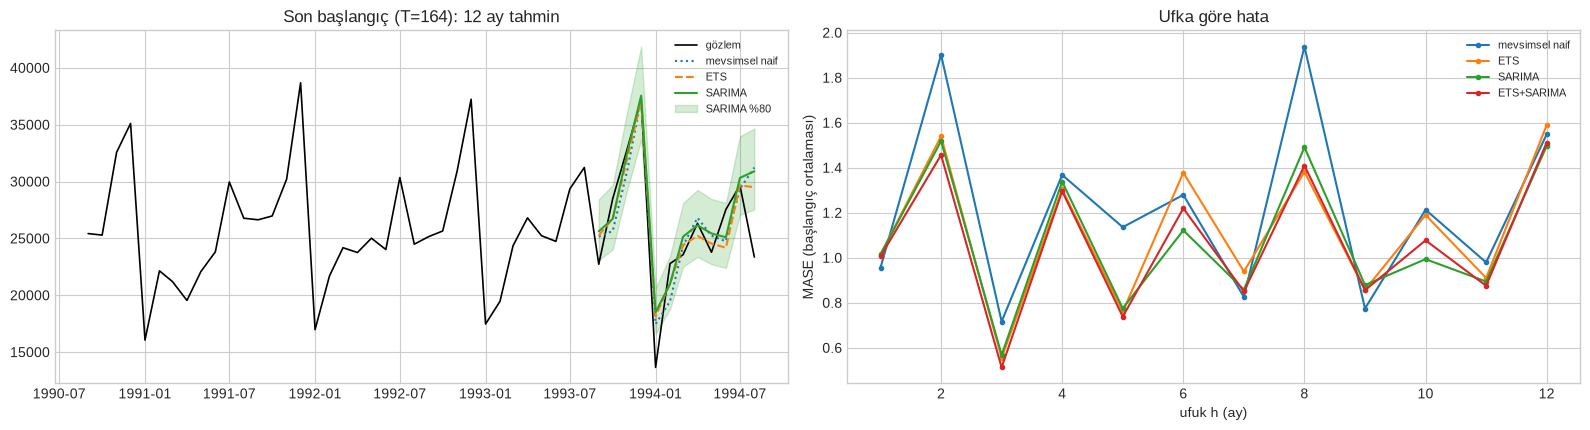

Ljung–Box (son başlangıçta seçilen SARIMA ((2, 1, 2), (1, 1, 1, 12))): gecikme 12 p=0.146, gecikme 24 p=0.105
YORUM: En düşük ortalama MASE: ETS+SARIMA (1.067); mevsimsel naif 1.220. Eşleşik (aynı başlangıç) farklar, MASE birimiyle ± std. hata: ETS−SARIMA = +0.039 ± 0.032 | SARIMA−mevsimsel naif = -0.141 ± 0.060 | birleşim−SARIMA = -0.012 ± 0.015.
       (Başlangıçlar örtüşen veriyi paylaşır; std. hatalar bağımsız örnek varsayar, yani iyimserdir. Kabaca |fark| < 2 std. hata ise sıralama gürültüden ayırt edilemez.)
       Sonuç: karmaşık modeller mevsimsel naiften iyi (1.08 ve 1.12 vs 1.22); ETS ile SARIMA arasında ayırt edilebilir bir fark yok. Birleşim SARIMA'dan belirgin biçimde iyi değil; kazanım küçük.
       SARIMA %80 aralıkları ortalama 0.76 kapsıyor (nominal 0.80): kabaca kalibre. Başlangıç sayısı küçük olduğundan bu oran da gürültülüdür.


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.4))
o = last['o']; ix = wine.index
ax[0].plot(ix[o - 36:o + H], wine.values[o - 36:o + H], 'k', lw=1.2, label='gözlem'); xs = ix[o:o + H]
for k, st in [('mevsimsel naif', ':'), ('ETS', '--'), ('SARIMA', '-')]: ax[0].plot(xs, last['f'][k], st, label=k)
ax[0].fill_between(xs, last['ci'][:, 0], last['ci'][:, 1], color='C2', alpha=.2, label='SARIMA %80'); ax[0].legend(fontsize=8); ax[0].set_title(f'Son başlangıç (T={o}): 12 ay tahmin')
hh = np.arange(1, H + 1)
for k in ['mevsimsel naif', 'ETS', 'SARIMA', 'ETS+SARIMA']: ax[1].plot(hh, np.mean(rec[k], axis=0), marker='o', ms=3, label=k)
ax[1].set(xlabel='ufuk h (ay)', ylabel='MASE (başlangıç ortalaması)', title='Ufka göre hata'); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

lb = acorr_ljungbox(last['res'].resid[13:], lags=[12, 24], model_df=sum([last['cfg'][0][0], last['cfg'][0][2], last['cfg'][1][0], last['cfg'][1][2]]))
print(f"Ljung–Box (son başlangıçta seçilen SARIMA {last['cfg']}): gecikme 12 p={lb.lb_pvalue.iloc[0]:.3f}, gecikme 24 p={lb.lb_pvalue.iloc[1]:.3f}")
best_k = tab_c.MASE_ort.idxmin(); sn_ = tab_c.loc['mevsimsel naif', 'MASE_ort']
pm = lambda a, b: (lambda d: (d.mean(), d.std(ddof=1) / np.sqrt(len(d))))(np.array([x.mean() - y.mean() for x, y in zip(rec[a], rec[b])]))
d_es, se_es = pm('ETS', 'SARIMA'); d_sn, se_sn = pm('SARIMA', 'mevsimsel naif'); d_cb, se_cb = pm('ETS+SARIMA', 'SARIMA')
print(f"YORUM: En düşük ortalama MASE: {best_k} ({tab_c.MASE_ort.min():.3f}); mevsimsel naif {sn_:.3f}. Eşleşik (aynı başlangıç) farklar, MASE birimiyle ± std. hata: ETS−SARIMA = {d_es:+.3f} ± {se_es:.3f} | SARIMA−mevsimsel naif = {d_sn:+.3f} ± {se_sn:.3f} | birleşim−SARIMA = {d_cb:+.3f} ± {se_cb:.3f}.")
print("       (Başlangıçlar örtüşen veriyi paylaşır; std. hatalar bağımsız örnek varsayar, yani iyimserdir. Kabaca |fark| < 2 std. hata ise sıralama gürültüden ayırt edilemez.)")
print(f"       Sonuç: karmaşık modeller mevsimsel naiften iyi ({tab_c.loc['SARIMA','MASE_ort']:.2f} ve {tab_c.loc['ETS','MASE_ort']:.2f} vs {sn_:.2f}); ETS ile SARIMA arasında " + ("ayırt edilebilir bir fark yok." if abs(d_es) < 2 * se_es else "ayırt edilebilir bir fark var.") + " Birleşim " + ("SARIMA'dan belirgin biçimde iyi." if d_cb < -2 * se_cb else "SARIMA'dan belirgin biçimde iyi değil; kazanım küçük."))
print(f"       SARIMA %80 aralıkları ortalama {np.mean(pi_cover):.2f} kapsıyor (nominal 0.80): " + ("kabaca kalibre." if abs(np.mean(pi_cover) - .8) < .07 else "kalibrasyon sapması var.") + " Başlangıç sayısı küçük olduğundan bu oran da gürültülüdür.")

## Adım 4 · Haftalık Benzin: Kesirli Mevsimsellik, Fourier ve ML (direct vs recursive)

**Veri:** ABD haftalık benzin tedariki (1.355 hafta). Bir yıl **52,18 hafta**: tam sayı olmayan periyot SARIMA'nın $m=52$ varsayımına tam oturmaz ve $m=52$ mevsimsel gecikmeler çok parametre ister. Bunun yerine **dynamic harmonic regression** kullanıyoruz: $K=6$ Fourier çifti (12 regresör) + ARIMA(2,1,1) hataları.

**Protokol:** son 208 haftada 4 haftada bir başlangıç (**53 başlangıç**), ufuklar $h\in\{1,4,13,26\}$ hafta. Her başlangıçta modeller yalnızca o ana kadarki veriyle eğitilir. Karşılaştırılanlar:

- **mevsimsel naif** ($y_{T+h-52}$) ve **naif**,
- **ARIMA+Fourier** (`SARIMAX`),
- **Ridge-direct** ve **LightGBM-direct** (her ufuk için ayrı model; öznitelikler: $y_t,\dots,y_{t-3}$, hedef tarihin geçen yılki değeri $y_{t+h-52}$ ve ondan bugünkü yıllık değişim, 4 ve 52 haftalık ortalama, Fourier),
- **LightGBM-direct-Δ:** hedef $y_{t+h}-y_{t+h-52}$ (geçen yıla göre **değişim**) — ağaçlar için trend/seviye sorununu azaltma hilesi,
- **LightGBM-recursive:** tek bir 1-adım modeli kendi tahminini girdi yaparak 26 adım ilerler.

Benzin: 1355 hafta, 1991-02-04 → 2017-01-16 | aralık değerleri: {Timedelta('7 days 00:00:00'): 1354} | eksik değer: 0
Yıllık ortalama (milyon varil/gün): 1992 7.29 → zirve 2007 9.35 → sonraki dip 2012 8.63 → 2016 9.35 (trend tek yönlü değil: yükseliş, düşüş, toparlanma)


STL(period=52) mevsimsellik gücü 0.59, trend gücü 0.91


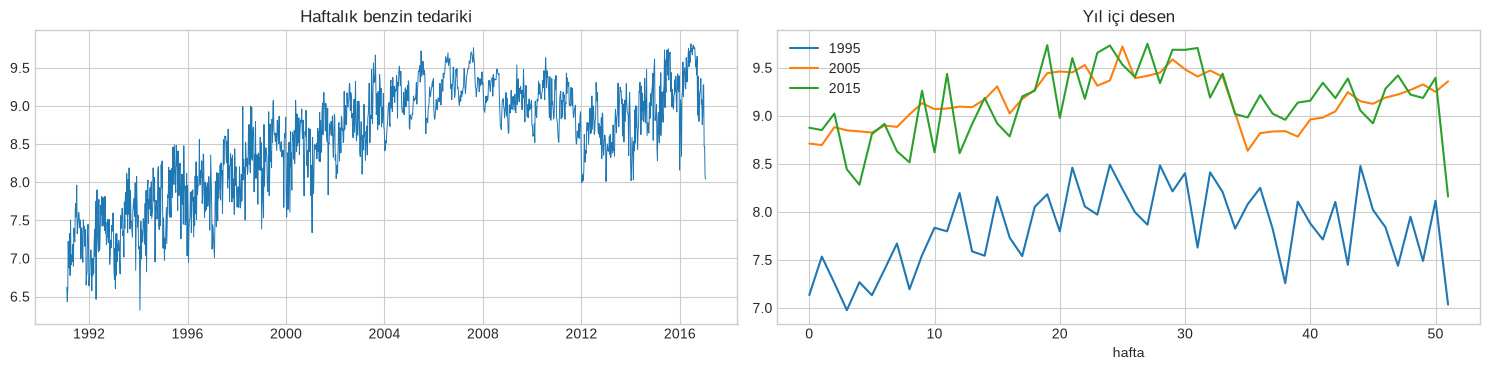

53 başlangıç: T=1120 … 1328 (ilk tahmin haftası 2012-07-30)
Sızıntı testi: origin sonrasını 999 yapınca öznitelikler değişti mi? maks. fark = 0.0


In [9]:
g = pd.read_csv('data/us_gasoline.csv'); g['date'] = [dt.datetime.strptime(s + ' 1', '%G W%V %u') for s in g.Week]
gas = g.set_index('date').Barrels.astype(float); vg = gas.values; ng = len(vg); PER = 52.1775
gaps = gas.index.to_series().diff().dropna().value_counts()
print(f"Benzin: {ng} hafta, {gas.index[0]:%Y-%m-%d} → {gas.index[-1]:%Y-%m-%d} | aralık değerleri: {gaps.to_dict()} | eksik değer: {int(gas.isna().sum())}")
ann = gas.groupby(gas.index.year).mean(); full = ann.loc[1992:2016]; pk = full.idxmax(); after = full.loc[pk:]; tr_y = after.idxmin()
print(f"Yıllık ortalama (milyon varil/gün): 1992 {full.loc[1992]:.2f} → zirve {pk} {full.max():.2f} → sonraki dip {tr_y} {after.min():.2f} → 2016 {full.loc[2016]:.2f} (trend tek yönlü değil: yükseliş, düşüş, toparlanma)")
stl_g = STL(gas, period=52, robust=True).fit()
FSg = max(0, 1 - stl_g.resid.var() / (stl_g.seasonal + stl_g.resid).var()); FTg = max(0, 1 - stl_g.resid.var() / (stl_g.trend + stl_g.resid).var())
print(f"STL(period=52) mevsimsellik gücü {FSg:.2f}, trend gücü {FTg:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8)); ax[0].plot(gas, lw=.7); ax[0].set_title('Haftalık benzin tedariki')
for yr in (1995, 2005, 2015): s_ = gas[str(yr)]; ax[1].plot(np.arange(len(s_)), s_.values, label=str(yr))
ax[1].set(title='Yıl içi desen', xlabel='hafta'); ax[1].legend(); plt.tight_layout(); plt.show()

def four(t, K=6):
    t = np.asarray(t, float); return np.column_stack([f(2 * np.pi * k * t / PER) for k in range(1, K + 1) for f in (np.sin, np.cos)])

def X_from(arr, t0, h):
    """Origin indeksleri t0 için öznitelikler; hedef t0+h. YALNIZCA arr[:max(t0)+1] ve arr[tg-52] (<= origin) kullanılır."""
    t0 = np.atleast_1d(t0); tg = t0 + h
    rm4 = np.array([arr[i - 3:i + 1].mean() for i in t0]); rm52 = np.array([arr[i - 51:i + 1].mean() for i in t0])
    return np.column_stack([arr[t0], arr[t0 - 1], arr[t0 - 2], arr[t0 - 3], arr[tg - 52], arr[tg - 52] - arr[t0 - 52], rm4, rm52, four(tg)])

mk_lgb = lambda: lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=10, verbose=-1, random_state=0, n_jobs=2)
HS = [1, 4, 13, 26]; HMAX = 26
origins_g = list(range(ng - HMAX - 1 - 208, ng - HMAX, 4)); print(f"{len(origins_g)} başlangıç: T={origins_g[0]} … {origins_g[-1]} (ilk tahmin haftası {gas.index[origins_g[0]+1]:%Y-%m-%d})")

# sızıntı kontrolü: yeniden yapılandırılmış öznitelikler, origin sonrası veriyi değiştirince DEĞİŞMEMELİ
o_ = origins_g[10]; v2 = vg.copy(); v2[o_ + 1:] = 999.0
chk = np.abs(X_from(vg[:o_ + 1], np.array([o_]), 13) - X_from(v2[:o_ + 1], np.array([o_]), 13)).max()
print(f"Sızıntı testi: origin sonrasını 999 yapınca öznitelikler değişti mi? maks. fark = {chk}")

süre 115 s | SARIMAX uyarı sayısı (yakalandı): 0
                  h=1    h=4   h=13   h=26
naif            0.786  0.916  1.481  1.531
mevsimsel naif  1.243  1.058  1.210  1.202
ARIMA+Fourier   0.726  0.690  0.956  0.991
Ridge-direct    0.745  0.644  0.930  0.960
LGBM-direct     0.756  0.706  0.939  0.877
LGBM-direct-Δ   0.806  0.755  0.956  0.889
LGBM-recursive  0.756  0.710  1.038  1.040


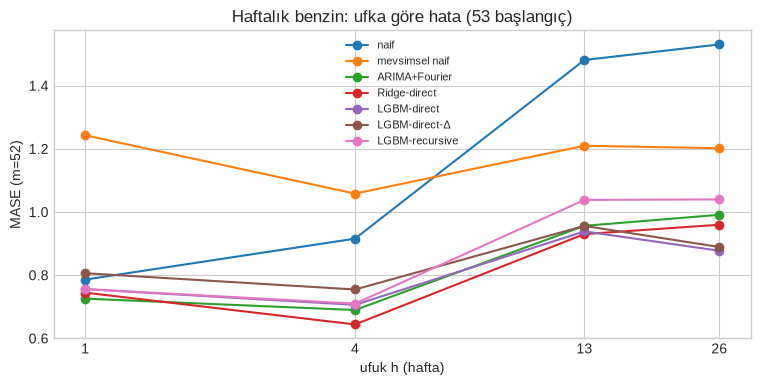

In [10]:
t0 = time.time(); errg = {k: {h: [] for h in HS} for k in ['naif', 'mevsimsel naif', 'ARIMA+Fourier', 'Ridge-direct', 'LGBM-direct', 'LGBM-direct-Δ', 'LGBM-recursive']}
preds_last = {}; nw_g = 0
for o in origins_g:
    arr = vg[:o + 1]; scale = np.mean(np.abs(arr[52:] - arr[:-52]))
    # --- ARIMA + Fourier ---
    res, nw = quiet(lambda: SARIMAX(arr, exog=four(np.arange(o + 1)), order=(2, 1, 1)).fit(disp=0, maxiter=60)); nw_g += nw
    fa = res.forecast(HMAX, exog=four(np.arange(o + 1, o + 1 + HMAX)))
    # --- recursive: tek 1-adım modeli ---
    ti1 = np.arange(60, o); m1 = mk_lgb().fit(X_from(arr, ti1, 1), arr[ti1 + 1])
    buf = list(arr)
    for hh in range(HMAX):
        ba = np.array(buf); buf.append(m1.predict(X_from(ba, np.array([len(ba) - 1]), 1))[0])
    rec_f = np.array(buf[o + 1:])
    for h in HS:
        a = vg[o + h]; ti = np.arange(60, o - h + 1)
        errg['naif'][h].append(abs(a - arr[-1]) / scale); errg['mevsimsel naif'][h].append(abs(a - vg[o + h - 52]) / scale)
        errg['ARIMA+Fourier'][h].append(abs(a - fa[h - 1]) / scale); errg['LGBM-recursive'][h].append(abs(a - rec_f[h - 1]) / scale)
        Xtr, Xte = X_from(arr, ti, h), X_from(arr, np.array([o]), h)
        p_r = Ridge(1.0).fit((Xtr - Xtr.mean(0)) / (Xtr.std(0) + 1e-9), arr[ti + h]).predict((Xte - Xtr.mean(0)) / (Xtr.std(0) + 1e-9))[0]
        p_l = mk_lgb().fit(Xtr, arr[ti + h]).predict(Xte)[0]
        p_d = mk_lgb().fit(Xtr, arr[ti + h] - arr[ti + h - 52]).predict(Xte)[0] + arr[o + h - 52]
        for k, p in [('Ridge-direct', p_r), ('LGBM-direct', p_l), ('LGBM-direct-Δ', p_d)]: errg[k][h].append(abs(a - p) / scale)
print(f"süre {time.time()-t0:.0f} s | SARIMAX uyarı sayısı (yakalandı): {nw_g}")

tab_g = pd.DataFrame({k: {f'h={h}': np.mean(v_[h]) for h in HS} for k, v_ in errg.items()}).T
print(tab_g.round(3).to_string())
def paired(a, b, h): d = np.array(errg[a][h]) - np.array(errg[b][h]); return d.mean(), d.std(ddof=1) / np.sqrt(len(d))
fig, ax = plt.subplots(1, 1, figsize=(9, 4))
for k in tab_g.index: ax.plot(HS, tab_g.loc[k].values, marker='o', label=k)
ax.set(xlabel='ufuk h (hafta)', ylabel='MASE (m=52)', title='Haftalık benzin: ufka göre hata (53 başlangıç)', xscale='log'); ax.set_xticks(HS); ax.set_xticklabels(HS); ax.legend(fontsize=8); plt.show()

In [11]:
best_h = {f'h={h}': tab_g[f'h={h}'].idxmin() for h in HS}; print("Her ufukta en iyi:", best_h)
nn = [k for k in tab_g.index if k not in ('naif', 'mevsimsel naif')]
for h in (1, 26):
    d, se = paired('LGBM-direct', 'mevsimsel naif', h); d1, se1 = paired('LGBM-direct', 'ARIMA+Fourier', h); d1b, se1b = paired('LGBM-direct', 'Ridge-direct', h)
    d2, se2 = paired('LGBM-direct-Δ', 'LGBM-direct', h); d3, se3 = paired('LGBM-recursive', 'LGBM-direct', h)
    print(f"h={h:2d}: LGBM-direct − mevsimsel naif = {d:+.3f} ± {se:.3f} | − ARIMA+Fourier = {d1:+.3f} ± {se1:.3f} | − Ridge-direct = {d1b:+.3f} ± {se1b:.3f} | Δ-hedef − seviye hedefi = {d2:+.3f} ± {se2:.3f} | recursive − direct = {d3:+.3f} ± {se3:.3f}")
sp1 = tab_g.loc[nn, 'h=1'].max() - tab_g.loc[nn, 'h=1'].min(); sp26 = tab_g.loc[nn, 'h=26'].max() - tab_g.loc[nn, 'h=26'].min()
print(f"YORUM: h=1'de beş yöntem ({', '.join(nn)}) {tab_g.loc[nn,'h=1'].min():.2f}-{tab_g.loc[nn,'h=1'].max():.2f} bandında (aralık {sp1:.2f}); en iyi {best_h['h=1']}. Naif {tab_g.loc['naif','h=1']:.2f} ile onlara çok yakın: bir hafta ilerisi için son değer zaten güçlü bir tahmin. Ufuk büyüyünce naif {tab_g.loc['naif','h=26']:.2f}'e çıkıyor: son gözlemin değeri sönüyor.")
print(f"       h=26'da en iyi {best_h['h=26']} ({tab_g['h=26'].min():.2f}); ML ve ARIMA+Fourier modelleri arasındaki aralık {sp26:.2f}. LGBM-direct − ARIMA+Fourier farkı h=26'da yukarıdaki satırda: |fark| < 2 std. hata ise sıralama gürültüdür.")
print(f"       Mevsimsel naif tüm ufuklarda {tab_g.loc['mevsimsel naif'].min():.2f}-{tab_g.loc['mevsimsel naif'].max():.2f} (MASE>1: eğitimdeki 'geçen yılın aynı haftası' hatasından kötü); kesirli periyot (52,18 hafta) yüzünden lag-52 her yıl ~0,18 hafta kayıyor — bu kaymanın payı ayrıca sınanmadı. Fourier'li modeller kayma sorununu yaşamıyor.")
print(f"       Δ-hedefi (geçen yıla göre değişim) bu seride seviye hedefini {'iyileştirmedi' if (paired('LGBM-direct-Δ','LGBM-direct',1)[0] > 0 and paired('LGBM-direct-Δ','LGBM-direct',26)[0] > 0) else 'iyileştirdi'} (h=1 ve h=26 satırları); ağaçların trend sorunu burada baskın değilmiş (Adım 5'te kontrollü olarak göreceğiz). Recursive, h=26'da direct'ten {paired('LGBM-recursive','LGBM-direct',26)[0]:+.3f} farklı (kısa ufukta aynı model olduğundan fark 0): hata birikimi uzun ufukta ortaya çıkıyor.")
print("       53 başlangıç örtüşen veri paylaştığı için std. hatalar iyimser; ±2 std. hata içindeki farkları yorumlamayın.")

Her ufukta en iyi: {'h=1': 'ARIMA+Fourier', 'h=4': 'Ridge-direct', 'h=13': 'Ridge-direct', 'h=26': 'LGBM-direct'}
h= 1: LGBM-direct − mevsimsel naif = -0.487 ± 0.106 | − ARIMA+Fourier = +0.030 ± 0.059 | − Ridge-direct = +0.011 ± 0.050 | Δ-hedef − seviye hedefi = +0.050 ± 0.033 | recursive − direct = +0.000 ± 0.000
h=26: LGBM-direct − mevsimsel naif = -0.324 ± 0.086 | − ARIMA+Fourier = -0.114 ± 0.066 | − Ridge-direct = -0.082 ± 0.055 | Δ-hedef − seviye hedefi = +0.012 ± 0.033 | recursive − direct = +0.163 ± 0.051
YORUM: h=1'de beş yöntem (ARIMA+Fourier, Ridge-direct, LGBM-direct, LGBM-direct-Δ, LGBM-recursive) 0.73-0.81 bandında (aralık 0.08); en iyi ARIMA+Fourier. Naif 0.79 ile onlara çok yakın: bir hafta ilerisi için son değer zaten güçlü bir tahmin. Ufuk büyüyünce naif 1.53'e çıkıyor: son gözlemin değeri sönüyor.
       h=26'da en iyi LGBM-direct (0.88); ML ve ARIMA+Fourier modelleri arasındaki aralık 0.16. LGBM-direct − ARIMA+Fourier farkı h=26'da yukarıdaki satırda: |fark| < 2 std.

## Adım 5 · Ağaçlar Trendi Ekstrapole Edemez (Sentetik Deney)

Gerçek veride trendin ne zaman yön değiştirdiğini bilmediğimizden, mekanizmayı **bilinen bir sentetik seri** üzerinde izole ediyoruz: $y_t=0{,}05\,t+2\sin(2\pi t/12)+\varepsilon_t$, $\varepsilon\sim\mathcal{N}(0,0{,}3^2)$, $t=0..299$. İlk 200 gözlemle eğit, sonraki 100'ü tahmin et. Öznitelikler: $t$, $\sin,\cos(2\pi t/12)$.

- **RF(t, mevsim):** ağaç, eğitimde görülmemiş $t>200$ için son yaprağın değerini verir ⇒ tahmin düzleşir.
- **Ridge(t, mevsim):** doğrusal trend sürer.
- **Hibrit:** önce OLS ile trendi çıkar, **artık**ı RF ile modelle, tahminde trendi geri ekle.
- **RF, fark hedefi:** $y_{t+1}-y_t$'yi lag öznitelikleriyle tahmin et (özyinelemeyle birikimli); ekstrapolasyon sorununu hedefi değiştirerek aşar.

Test MAE (t=200..299), gürültü sd=0.3 ⇒ ulaşılabilir MAE ≈ 0.24:
RF(t, mevsim)                           2.747
Ridge(t, mevsim)                        0.237
Hibrit: OLS trend + RF(artık)           0.248
RF lag, seviye hedefi (özyinelemeli)    1.568
RF lag, fark hedefi (özyinelemeli)      0.295
Eğitim aralığı maks. y = 11.98; test aralığı maks. y = 17.02; RF(t, mevsim) tahmin maks. = 11.34


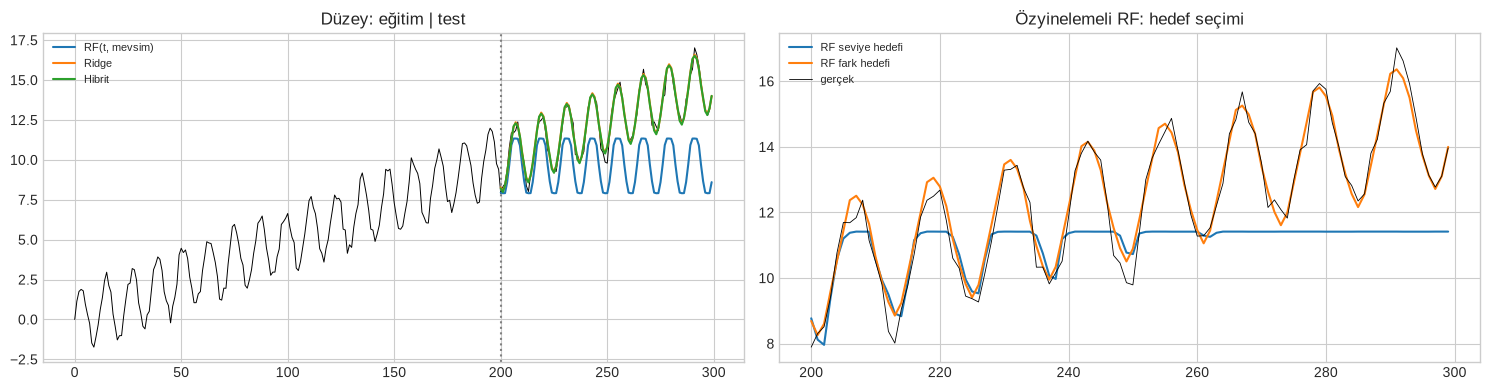

YORUM: RF(t, mevsim) test maks. y=17.0 iken en fazla 11.3 tahmin ediyor (eğitim maks. 12.0'in ötesine geçemiyor): MAE 2.75 vs Ridge 0.24.
       Çözüm 1 (hibrit): trendi doğrusal bileşene ver, ağaca yalnızca trend-çıkarılmış kalıntıyı bırak (MAE 0.25; ulaşılabilir ≈0.24). Çözüm 2: hedefi farka çevir (özyinelemeli MAE 0.30 vs seviye hedefi 1.57) — ağaç artık trendi 'görmek' zorunda değil, ama özyinelemede hata birikir (0.30 > hibrit/Ridge).
       Pratik kural: trend yapısı biliniyorsa onu açıkça modelle (Ridge/Fourier+trend), ağaca artığı ver; gerçek seride (Adım 4) trend tek yönlü olmadığından fark hedefi ayrıca sınanmalı — orada kazanç görmedik.


In [12]:
rs = np.random.default_rng(7); tt = np.arange(300); ysyn = 0.05 * tt + 2 * np.sin(2 * np.pi * tt / 12) + rs.normal(0, 0.3, 300)
Xs = np.column_stack([tt, np.sin(2 * np.pi * tt / 12), np.cos(2 * np.pi * tt / 12)]); ntr = 200
mae = lambda a, b: np.mean(np.abs(a - b))
rf = RandomForestRegressor(300, min_samples_leaf=3, random_state=0, n_jobs=2).fit(Xs[:ntr], ysyn[:ntr]); p_rf = rf.predict(Xs[ntr:])
p_ri = Ridge(1e-6).fit(Xs[:ntr], ysyn[:ntr]).predict(Xs[ntr:])
trend_fit = np.polyfit(tt[:ntr], ysyn[:ntr], 1); res_tr = ysyn[:ntr] - np.polyval(trend_fit, tt[:ntr])
rf_h = RandomForestRegressor(300, min_samples_leaf=3, random_state=0, n_jobs=2).fit(Xs[:ntr, 1:], res_tr); p_hy = rf_h.predict(Xs[ntr:, 1:]) + np.polyval(trend_fit, tt[ntr:])
# fark hedefi, özyinelemeli: öznitelik = [y_{t}, y_{t-1}, y_{t-11}, sin, cos]; hedef = y_{t+1} - y_t
rows = np.arange(12, ntr - 1)
Xd = np.array([[ysyn[i], ysyn[i - 1], ysyn[i - 11], np.sin(2 * np.pi * (i + 1) / 12), np.cos(2 * np.pi * (i + 1) / 12)] for i in rows]); yd = ysyn[rows + 1] - ysyn[rows]
rf_d = RandomForestRegressor(300, min_samples_leaf=3, random_state=0, n_jobs=2).fit(Xd, yd)
rf_lv = RandomForestRegressor(300, min_samples_leaf=3, random_state=0, n_jobs=2).fit(Xd, ysyn[rows + 1])
def recurse(model, diff):
    b = list(ysyn[:ntr]); 
    for t_ in range(ntr - 1, 299):
        x_ = np.array([[b[t_], b[t_ - 1], b[t_ - 11], np.sin(2 * np.pi * (t_ + 1) / 12), np.cos(2 * np.pi * (t_ + 1) / 12)]]); pr = model.predict(x_)[0]
        b.append(b[t_] + pr if diff else pr)
    return np.array(b[ntr:])
p_rd = recurse(rf_d, True); p_rl = recurse(rf_lv, False)
yt = ysyn[ntr:]
tab5 = pd.Series({'RF(t, mevsim)': mae(yt, p_rf), 'Ridge(t, mevsim)': mae(yt, p_ri), 'Hibrit: OLS trend + RF(artık)': mae(yt, p_hy), 'RF lag, seviye hedefi (özyinelemeli)': mae(yt, p_rl), 'RF lag, fark hedefi (özyinelemeli)': mae(yt, p_rd)})
print("Test MAE (t=200..299), gürültü sd=0.3 ⇒ ulaşılabilir MAE ≈ 0.24:"); print(tab5.round(3).to_string())
print(f"Eğitim aralığı maks. y = {ysyn[:ntr].max():.2f}; test aralığı maks. y = {yt.max():.2f}; RF(t, mevsim) tahmin maks. = {p_rf.max():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(15, 4)); ax[0].plot(tt, ysyn, 'k', lw=.7); ax[0].axvline(ntr, c='gray', ls=':')
for nm, p in [('RF(t, mevsim)', p_rf), ('Ridge', p_ri), ('Hibrit', p_hy)]: ax[0].plot(tt[ntr:], p, label=nm)
ax[0].legend(fontsize=8); ax[0].set_title('Düzey: eğitim | test'); 
for nm, p in [('RF seviye hedefi', p_rl), ('RF fark hedefi', p_rd)]: ax[1].plot(tt[ntr:], p, label=nm)
ax[1].plot(tt[ntr:], yt, 'k', lw=.6, label='gerçek'); ax[1].legend(fontsize=8); ax[1].set_title('Özyinelemeli RF: hedef seçimi'); plt.tight_layout(); plt.show()
print(f"YORUM: RF(t, mevsim) test maks. y={yt.max():.1f} iken en fazla {p_rf.max():.1f} tahmin ediyor (eğitim maks. {ysyn[:ntr].max():.1f}'in ötesine geçemiyor): MAE {tab5.iloc[0]:.2f} vs Ridge {tab5.iloc[1]:.2f}.")
print(f"       Çözüm 1 (hibrit): trendi doğrusal bileşene ver, ağaca yalnızca trend-çıkarılmış kalıntıyı bırak (MAE {tab5.iloc[2]:.2f}; ulaşılabilir ≈0.24). Çözüm 2: hedefi farka çevir (özyinelemeli MAE {tab5.iloc[4]:.2f} vs seviye hedefi {tab5.iloc[3]:.2f}) — ağaç artık trendi 'görmek' zorunda değil, ama özyinelemede hata birikir (0.30 > hibrit/Ridge).")
print("       Pratik kural: trend yapısı biliniyorsa onu açıkça modelle (Ridge/Fourier+trend), ağaca artığı ver; gerçek seride (Adım 4) trend tek yönlü olmadığından fark hedefi ayrıca sınanmalı — orada kazanç görmedik.")

## Adım 6 · Melbourne Günlük Sıcaklık: Sızıntı ve Belirsizlik

3.650 günlük minimum sıcaklık (1981–1990). **Hedef:** yarının minimum sıcaklığı. Önce taban çizgileri (dünü tekrarla, mevsimsel iklim eğrisi), sonra LightGBM. İki deney:

1. **Sızıntı:** dürüst öznitelikler vs `rolling(7, center=True)` (geleceğe 3 gün bakar) — CV puanı ne kadar "iyileşiyor"? Ayrıca karıştırılmış `KFold` ile `TimeSeriesSplit` farkı.
2. **Aralıklar:** %90 aralık için (a) eğitim artıklarından Gauss, (b) quantile LightGBM, (c) split-conformal, (d) conformalized quantile regression (CQR); **zaman-sıralı test kümesinde kapsama** ve genişlik.

In [13]:
tmp_raw = pd.read_csv('data/melb_temp.csv', parse_dates=['Date']).set_index('Date').Temp
tmp = tmp_raw.asfreq('D'); n_miss = int(tmp.isna().sum()); tmp = tmp.interpolate()
print(f"Melbourne: {len(tmp_raw)} gözlem → tam günlük ızgarada {len(tmp)} gün ({n_miss} eksik gün doğrusal interpolasyonla dolduruldu) | ort. {tmp.mean():.1f} °C, sd {tmp.std():.1f}, min {tmp.min():.1f}, maks {tmp.max():.1f}")
mm = tmp.groupby(tmp.index.month).agg(['mean', 'std']).round(2); print("Aylık ortalama (sd): " + ", ".join(f"{m}:{r['mean']:.1f}({r['std']:.1f})" for m, r in mm.iterrows()))
ac1 = tmp.autocorr(1); print(f"Otokorelasyon: gecikme 1 = {ac1:.2f}, 7 = {tmp.autocorr(7):.2f}, 365 = {tmp.autocorr(365):.2f}")

def make_feats(s, leak=False):
    d = pd.DataFrame({'y': s.shift(-1)})
    for l in range(0, 7): d[f'lag{l}'] = s.shift(l)
    d['rm7'] = s.rolling(7).mean(); d['rm30'] = s.rolling(30).mean()
    doy = s.index.day_of_year.values; d['sin1'] = np.sin(2 * np.pi * doy / 365.25); d['cos1'] = np.cos(2 * np.pi * doy / 365.25)
    if leak: d['rm7_center'] = s.rolling(7, center=True).mean()          # t+1..t+3 değerlerini içerir -> SIZINTI
    return d.dropna()
mk_l2 = lambda: lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=0, n_jobs=2)

rows = []
for leak in (False, True):
    d = make_feats(tmp, leak); X, yv = d.drop(columns='y'), d.y
    for nm, cv in [('KFold (karıştırılmış)', KFold(5, shuffle=True, random_state=0)), ('TimeSeriesSplit (test=365 gün)', TimeSeriesSplit(5, test_size=365))]:
        maes = [np.abs(mk_l2().fit(X.iloc[a], yv.iloc[a]).predict(X.iloc[b]) - yv.iloc[b]).mean() for a, b in cv.split(X)]
        rows.append(dict(öznitelikler='SIZINTILI (center=True)' if leak else 'dürüst', CV=nm, MAE=np.mean(maes), sd=np.std(maes, ddof=1)))
tab_cv = pd.DataFrame(rows); print(tab_cv.round(3).to_string(index=False))
d = make_feats(tmp); print(f"Dürüst özniteliklerle dünü tekrarla (persistence) MAE = {np.abs(d.y - d.lag0).mean():.3f} °C")
h_ = tab_cv.set_index(['öznitelikler', 'CV']).MAE
print(f"YORUM: Sızıntılı öznitelik CV hatasını {h_[('dürüst','KFold (karıştırılmış)')]:.2f} → {h_[('SIZINTILI (center=True)','KFold (karıştırılmış)')]:.2f} (KFold) ve {h_[('dürüst','TimeSeriesSplit (test=365 gün)')]:.2f} → {h_[('SIZINTILI (center=True)','TimeSeriesSplit (test=365 gün)')]:.2f} (TimeSeriesSplit) düşürüyor: TimeSeriesSplit bile sızıntıyı yakalamaz, çünkü sızıntı bölmede değil ÖZNİTELİĞİN içinde.")
diff_ = h_[('dürüst', 'KFold (karıştırılmış)')] - h_[('dürüst', 'TimeSeriesSplit (test=365 gün)')]
print(f"       Dürüst öznitelikte karıştırılmış KFold ile TimeSeriesSplit arasındaki fark yalnızca {diff_:+.3f} °C (katlar arası sd ~{tab_cv.sd.iloc[1]:.2f}): bu TEK-adımlı, kısa-gecikmeli kurulumda karıştırma tek başına büyük bir iyimserlik yaratmadı. Bu 'karıştırma zararsızdır' demek değil — hedef/öznitelikler uzun pencere içerdiğinde (ör. 7 günlük ortalama hedef) ya da trend varken bozulur; yine de rolling-origin protokolü her durumda güvenli varsayılandır.")

Melbourne: 3650 gözlem → tam günlük ızgarada 3652 gün (2 eksik gün doğrusal interpolasyonla dolduruldu) | ort. 11.2 °C, sd 4.1, min 0.0, maks 26.3
Aylık ortalama (sd): 1:15.0(2.9), 2:15.4(2.7), 3:14.6(3.2), 4:12.1(3.1), 5:9.9(2.8), 6:7.3(2.6), 7:6.7(2.6), 8:7.9(2.3), 9:9.0(2.8), 10:10.3(2.7), 11:12.5(3.0), 12:13.9(2.5)
Otokorelasyon: gecikme 1 = 0.77, 7 = 0.58, 365 = 0.54


           öznitelikler                             CV   MAE    sd
                 dürüst          KFold (karıştırılmış) 1.884 0.038
                 dürüst TimeSeriesSplit (test=365 gün) 1.805 0.125
SIZINTILI (center=True)          KFold (karıştırılmış) 1.414 0.048
SIZINTILI (center=True) TimeSeriesSplit (test=365 gün) 1.347 0.076
Dürüst özniteliklerle dünü tekrarla (persistence) MAE = 2.129 °C
YORUM: Sızıntılı öznitelik CV hatasını 1.88 → 1.41 (KFold) ve 1.80 → 1.35 (TimeSeriesSplit) düşürüyor: TimeSeriesSplit bile sızıntıyı yakalamaz, çünkü sızıntı bölmede değil ÖZNİTELİĞİN içinde.
       Dürüst öznitelikte karıştırılmış KFold ile TimeSeriesSplit arasındaki fark yalnızca +0.079 °C (katlar arası sd ~0.12): bu TEK-adımlı, kısa-gecikmeli kurulumda karıştırma tek başına büyük bir iyimserlik yaratmadı. Bu 'karıştırma zararsızdır' demek değil — hedef/öznitelikler uzun pencere içerdiğinde (ör. 7 günlük ortalama hedef) ya da trend varken bozulur; yine de rolling-origin protokolü her durumd

eğitim 2527 | kalibrasyon 366 | test 729 gün
Test MAE (°C): {'dünü tekrarla': 1.955, 'iklim eğrisi (3 harmonik)': 2.013, 'Ridge (lag+takvim)': 1.719, 'LightGBM': 1.711}
Baz çizgisi 'dünü tekrarla'ya göre LightGBM iyileşmesi: %12.5; Ridge ile LightGBM farkı -0.009 °C: günlük sıcaklık için doğrusal model neredeyse yeterli (gürültü baskın).



Gauss sd: eğitim artığı 1.87 vs kalibrasyon artığı 2.39 °C | conformal q̂ = 4.18 | CQR düzeltmesi = +0.93
                     yöntem  kapsama  ort_genişlik  kapsama yaz (Ara-Şub)  kapsama kış (Haz-Ağu)
(a) Gauss, eğitim artığı sd    0.844         6.146                  0.860                  0.891
      (b) quantile LightGBM    0.845         6.544                  0.838                  0.859
        (c) split-conformal    0.949         8.354                  0.927                  0.984
                    (d) CQR    0.937         8.403                  0.939                  0.962


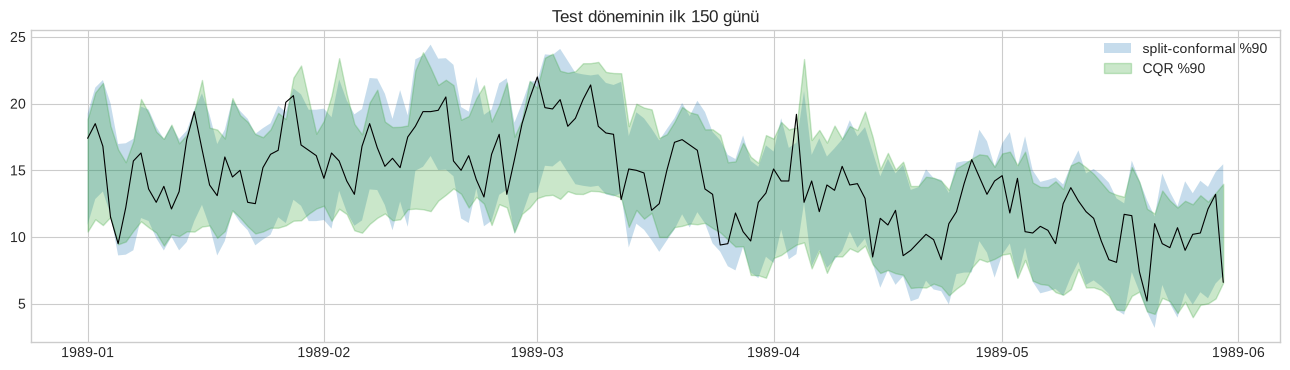

YORUM: Nominal kapsama 0.90. (a) Gauss, EĞİTİM artık sd'sini (1.87) kullanıyor; kalibrasyon yılı 2.39, test 2.16: eğitim hatası iyimser olduğundan aralık dar kalıyor (kapsama 0.84). (b) quantile LightGBM da 0.84: eğitim verisine uyan kantil modeli test dönemini yeterince kapsamıyor.
       (c) split-conformal 0.95 ve (d) CQR 0.94: nominalin ÜSTÜNDE (muhafazakâr). Olası neden: kalibrasyon yılı (1988) artık sd'si 2.39, test dönemininkinden (2.16) büyük; conformal garantisi kalibrasyon ve testin değiş-tokuşabilir olmasını ister, zaman serisinde bu yalnızca yaklaşıktır. Nominale en yakın: (d) CQR (0.937).
       Mevsimsel fark (kış−yaz kapsama): split-conformal +0.056, CQR +0.023; sabit genişlikli aralık gürültü mevsimle değişince bir mevsimi fazla kapsar. Test 729 gün (2 yıl, otokorele) olduğundan kapsama oranlarının belirsizliği ±0.03 mertebesindedir; küçük farkları yorumlamayın.


In [14]:
# Zaman-sıralı bölme: eğitim 1981-1987, kalibrasyon 1988, test 1989-1990
d = make_feats(tmp); X, yv = d.drop(columns='y'), d.y
is_tr = d.index < '1988-01-01'; is_ca = (d.index >= '1988-01-01') & (d.index < '1989-01-01'); is_te = d.index >= '1989-01-01'
print(f"eğitim {is_tr.sum()} | kalibrasyon {is_ca.sum()} | test {is_te.sum()} gün")
Xtr, ytr, Xca, yca, Xte, yte = X[is_tr], yv[is_tr], X[is_ca], yv[is_ca], X[is_te], yv[is_te]

# taban çizgileri ve ortalama modeller
doy = lambda ix: ix.day_of_year.values
fd = lambda ix: np.column_stack([np.sin(2 * np.pi * k * doy(ix) / 365.25) if j == 0 else np.cos(2 * np.pi * k * doy(ix) / 365.25) for k in (1, 2, 3) for j in (0, 1)])
clim = Ridge(1e-6).fit(fd(Xtr.index), ytr)
m_mean = mk_l2().fit(Xtr, ytr); m_ridge = Ridge(1.0).fit(Xtr, ytr)
res_ = {'dünü tekrarla': np.abs(yte - Xte.lag0).mean(), 'iklim eğrisi (3 harmonik)': np.abs(yte - clim.predict(fd(Xte.index))).mean(),
        'Ridge (lag+takvim)': np.abs(yte - m_ridge.predict(Xte)).mean(), 'LightGBM': np.abs(yte - m_mean.predict(Xte)).mean()}
print("Test MAE (°C):", {k: round(float(v), 3) for k, v in res_.items()})
print(f"Baz çizgisi 'dünü tekrarla'ya göre LightGBM iyileşmesi: %{100*(1-res_['LightGBM']/res_['dünü tekrarla']):.1f}; Ridge ile LightGBM farkı {res_['LightGBM']-res_['Ridge (lag+takvim)']:+.3f} °C: günlük sıcaklık için doğrusal model neredeyse yeterli (gürültü baskın).")

# --- aralıklar (%90) ---
alpha = 0.10; mu_te = m_mean.predict(Xte)
sig_in = np.std(ytr - m_mean.predict(Xtr)); sig_ca = np.std(yca - m_mean.predict(Xca))
q_lo = lgb.LGBMRegressor(objective='quantile', alpha=alpha / 2, n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=0, n_jobs=2).fit(Xtr, ytr)
q_hi = lgb.LGBMRegressor(objective='quantile', alpha=1 - alpha / 2, n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=0, n_jobs=2).fit(Xtr, ytr)
lo_q, hi_q = q_lo.predict(Xte), q_hi.predict(Xte)
sc = np.abs(yca - m_mean.predict(Xca)); k_ = int(np.ceil((1 - alpha) * (len(sc) + 1))); qhat = np.sort(sc)[k_ - 1]
E = np.maximum(q_lo.predict(Xca) - yca, yca - q_hi.predict(Xca)); k2 = int(np.ceil((1 - alpha) * (len(E) + 1))); qcqr = np.sort(E)[k2 - 1]
ints = {'(a) Gauss, eğitim artığı sd': (mu_te - 1.645 * sig_in, mu_te + 1.645 * sig_in), '(b) quantile LightGBM': (lo_q, hi_q),
        '(c) split-conformal': (mu_te - qhat, mu_te + qhat), '(d) CQR': (lo_q - qcqr, hi_q + qcqr)}
season = pd.Series(np.where(Xte.index.month.isin([12, 1, 2]), 'yaz (Ara-Şub)', np.where(Xte.index.month.isin([6, 7, 8]), 'kış (Haz-Ağu)', 'ara mevsim')), index=Xte.index)
rows = []
for nm, (lo, hi) in ints.items():
    cov = ((yte.values >= lo) & (yte.values <= hi)); r = dict(yöntem=nm, kapsama=cov.mean(), ort_genişlik=np.mean(hi - lo))
    for s_ in ['yaz (Ara-Şub)', 'kış (Haz-Ağu)']: r['kapsama ' + s_] = cov[(season == s_).values].mean()
    rows.append(r)
tab_pi = pd.DataFrame(rows); print(f"\nGauss sd: eğitim artığı {sig_in:.2f} vs kalibrasyon artığı {sig_ca:.2f} °C | conformal q̂ = {qhat:.2f} | CQR düzeltmesi = {qcqr:+.2f}")
print(tab_pi.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 1, figsize=(13, 3.8)); s_ix = Xte.index[:150]
ax.plot(s_ix, yte.values[:150], 'k', lw=.8); ax.fill_between(s_ix, ints['(c) split-conformal'][0][:150], ints['(c) split-conformal'][1][:150], alpha=.25, label='split-conformal %90'); ax.fill_between(s_ix, ints['(d) CQR'][0][:150], ints['(d) CQR'][1][:150], alpha=.25, color='C2', label='CQR %90')
ax.legend(); ax.set_title('Test döneminin ilk 150 günü'); plt.tight_layout(); plt.show()
best_cov = tab_pi.iloc[(tab_pi.kapsama - 0.9).abs().argsort()].yöntem.iloc[0]
sd_te = np.std(yte - mu_te); cs = tab_pi.set_index('yöntem')
print(f"YORUM: Nominal kapsama 0.90. (a) Gauss, EĞİTİM artık sd'sini ({sig_in:.2f}) kullanıyor; kalibrasyon yılı {sig_ca:.2f}, test {sd_te:.2f}: eğitim hatası iyimser olduğundan aralık dar kalıyor (kapsama {cs.kapsama.iloc[0]:.2f}). (b) quantile LightGBM da {cs.kapsama.iloc[1]:.2f}: eğitim verisine uyan kantil modeli test dönemini yeterince kapsamıyor.")
print(f"       (c) split-conformal {cs.kapsama.iloc[2]:.2f} ve (d) CQR {cs.kapsama.iloc[3]:.2f}: nominalin ÜSTÜNDE (muhafazakâr). Olası neden: kalibrasyon yılı (1988) artık sd'si {sig_ca:.2f}, test dönemininkinden ({sd_te:.2f}) {'büyük' if sig_ca > sd_te else 'küçük'}; conformal garantisi kalibrasyon ve testin değiş-tokuşabilir olmasını ister, zaman serisinde bu yalnızca yaklaşıktır. Nominale en yakın: {best_cov} ({cs.kapsama[best_cov]:.3f}).")
sw_c = cs.loc['(c) split-conformal', 'kapsama kış (Haz-Ağu)'] - cs.loc['(c) split-conformal', 'kapsama yaz (Ara-Şub)']; sw_d = cs.loc['(d) CQR', 'kapsama kış (Haz-Ağu)'] - cs.loc['(d) CQR', 'kapsama yaz (Ara-Şub)']
print(f"       Mevsimsel fark (kış−yaz kapsama): split-conformal {sw_c:+.3f}, CQR {sw_d:+.3f}; sabit genişlikli aralık gürültü mevsimle değişince bir mevsimi fazla kapsar. Test {len(yte)} gün (2 yıl, otokorele) olduğundan kapsama oranlarının belirsizliği ±0.03 mertebesindedir; küçük farkları yorumlamayın.")

# 📊 R Uygulaması

Zaman serisi tahmini R'da **`forecast`** paketinin (Hyndman) ana işidir: `auto.arima`, `ets`, `snaive`, `tslm` + `fourier`, `accuracy`. `wineind` zaten pakette hazır geliyor. Proje kararı gereği (bkz. [[notebook_style_convention]]) R bölümü kısa: önce Python'da **aynı tek bölme** (son 24 ay) için referans MASE'leri yazdırıyoruz, sonra 1 hücrede R ile aynı karşılaştırmayı yapıyoruz.

In [15]:
# Referans (Python): son 24 ay hold-out, eğitim = ilk 152 ay, MASE (m=12)
tr_w, te_w = wine[:-24], wine[-24:]
f_sn = np.tile(tr_w.values[-12:], 2); e_res, e_cfg = fit_ets_best(tr_w)
air_res = fit_sarima(np.log(tr_w), (0, 1, 1), (0, 1, 1, 12)); f_air = np.exp(air_res.get_forecast(24).predicted_mean.values)
print(f"Python (tek bölme, son 24 ay):  mevsimsel naif MASE = {mase(te_w, f_sn, tr_w, 12):.3f} | ETS {e_cfg} = {mase(te_w, e_res.forecast(24).values, tr_w, 12):.3f} | SARIMA airline (log) = {mase(te_w, f_air, tr_w, 12):.3f}")
print("R'da `auto.arima(lambda=0)` kendi mertebesini seçer (airline'dan farklı olabilir); sayılar yakın ama birebir aynı olması beklenmez. Tek bölme gürültülüdür — Adım 3'teki yürüyen başlangıç protokolü daha güvenilirdir.")

Python (tek bölme, son 24 ay):  mevsimsel naif MASE = 0.919 | ETS ('yok', '-', 'mul') = 0.753 | SARIMA airline (log) = 0.789
R'da `auto.arima(lambda=0)` kendi mertebesini seçer (airline'dan farklı olabilir); sayılar yakın ama birebir aynı olması beklenmez. Tek bölme gürültülüdür — Adım 3'teki yürüyen başlangıç protokolü daha güvenilirdir.


In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R -w 900 -h 420
# install.packages("forecast")  # ilk çalıştırmada gerekir
library(forecast)
train <- head(wineind, -24); test <- tail(wineind, 24)
f_sn  <- snaive(train, h = 24)
f_ets <- forecast(ets(train), h = 24)
f_ari <- forecast(auto.arima(train, lambda = 0, seasonal = TRUE), h = 24)
tab <- rbind(snaive = accuracy(f_sn, test)["Test set", c("MAE", "MASE")],
             ETS    = accuracy(f_ets, test)["Test set", c("MAE", "MASE")],
             auto.arima_log = accuracy(f_ari, test)["Test set", c("MAE", "MASE")])
print(round(tab, 3)); cat("seçilen ETS:", f_ets$method, "| seçilen ARIMA:", as.character(f_ari$method), "\n")
autoplot(f_ari) + autolayer(test, series = "gerçek")

# 🗄️ SQL Uygulaması (DuckDB)

Zaman serisi öznitelikleri veri ambarında **pencere fonksiyonlarıyla** üretilir (`LAG`, `AVG(...) OVER (ROWS BETWEEN ...)`). Proje kararı gereği (bkz. [[notebook_style_convention]]) iki kısa hücre:

1. **Gecikme/pencere öznitelikleri ve MASE:** `LAG(y,12)`, **geçmişe** bakan yuvarlanan ortalama (`ROWS BETWEEN 12 PRECEDING AND 1 PRECEDING`) ve eğitim MASE paydası; mevsimsel naif hold-out MASE'ini Python'la karşılaştırıyoruz. Karşıt örnek: `BETWEEN 3 PRECEDING AND 3 FOLLOWING` **sızıntıdır**.
2. **SES'i özyinelemeli CTE ile:** $\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1}$ — `WITH RECURSIVE` ile; Python'un `ses_levels` sonucuyla karşılaştırma.

In [18]:
import duckdb
con = duckdb.connect()
wdf = pd.DataFrame({'ds': wine.index, 'y': wine.values}); con.register('wine_t', wdf)

# --- SQL-1: pencere öznitelikleri + eğitim MASE paydası + hold-out MASE ---
feat_sql = con.execute("""
SELECT ds, y,
       LAG(y, 1)  OVER w AS lag1,
       LAG(y, 12) OVER w AS lag12,
       AVG(y) OVER (ORDER BY ds ROWS BETWEEN 12 PRECEDING AND 1 PRECEDING) AS rm12_gecmis,          -- dürüst: bugünü içermez
       AVG(y) OVER (ORDER BY ds ROWS BETWEEN 3 PRECEDING AND 3 FOLLOWING) AS rm7_merkez_SIZINTI       -- gelecek 3 ayı içerir
FROM wine_t WINDOW w AS (ORDER BY ds) ORDER BY ds
""").df()
print(feat_sql.iloc[[12, 13, 100]].assign(**{c: lambda d, c=c: d[c].round(1) for c in feat_sql.columns[1:]}).to_string(index=False))

cut = wine.index[-24]
res_sql = con.execute(f"""
WITH l AS (SELECT ds, y, LAG(y, 12) OVER (ORDER BY ds) AS y12 FROM wine_t),
scale AS (SELECT AVG(ABS(y - y12)) AS s FROM l WHERE ds < TIMESTAMP '{cut:%Y-%m-%d}' AND y12 IS NOT NULL),
fc AS (   -- mevsimsel naif tahmin: test ayı için eğitimin SON 12 AYINDAKİ aynı ayın değeri (ikinci test yılı için de aynı değer)
    SELECT t.ds, t.y, b.y AS yhat FROM wine_t t
    JOIN wine_t b ON b.ds = CASE WHEN t.ds < TIMESTAMP '{cut:%Y-%m-%d}' + INTERVAL 12 MONTH THEN t.ds - INTERVAL 12 MONTH ELSE t.ds - INTERVAL 24 MONTH END
    WHERE t.ds >= TIMESTAMP '{cut:%Y-%m-%d}'),
test AS (SELECT AVG(ABS(y - yhat)) AS mae FROM fc)
SELECT scale.s AS egitim_snaive_mae, test.mae AS test_mae, test.mae / scale.s AS mase FROM scale, test
""").df()
mase_py = mase(te_w, f_sn, tr_w, 12)
print(res_sql.round(4).to_string(index=False), f"| Python MASE = {mase_py:.4f}")
rm_py = wine.shift(1).rolling(12, min_periods=1).mean()
print(f"rm12_gecmis SQL vs pandas (shift(1).rolling(12)) maks. fark (t>=12): {np.abs(feat_sql.rm12_gecmis.values[12:] - rm_py.values[12:]).max():.2e}")
print("YORUM: SQL'in eğitim paydası ve hold-out MASE'i Python'la aynı. Yuvarlanan ortalamada 'geçmiş' çerçevesi (1 PRECEDING'de biter) `shift(1).rolling` ile birebir; `FOLLOWING` içeren çerçeve ise tek bir satırda bile geleceği taşıyor — özellik mühendisliği veri ambarında yapılıyorsa çerçeve sınırı kod incelemesinin ilk kontrol maddesi olmalı.")

# --- SQL-2: SES, özyinelemeli CTE ---
a_ = float(a_hat); l0_ = float(l0)
lw = pd.DataFrame({'t': np.arange(1, len(ys) + 1), 'y': ys}); con.register('lw', lw)
ses_sql = con.execute(f"""
WITH RECURSIVE ses(t, lvl) AS (
    SELECT 0, {l0_}::DOUBLE
    UNION ALL
    SELECT l.t, {a_} * l.y + (1 - {a_}) * ses.lvl FROM ses JOIN lw l ON l.t = ses.t + 1
)
SELECT t, lvl FROM ses ORDER BY t
""").df()
L_py = ses_levels(ys, a_, l0_)
print(f"\nSES özyinelemeli CTE: {len(ses_sql)} seviye | son seviye SQL {ses_sql.lvl.iloc[-1]:.8f} vs Python {L_py[-1]:.8f} | maks. fark {np.abs(ses_sql.lvl.values - L_py).max():.1e}")
print("YORUM: Özyinelemeli CTE, durum taşıyan (state-space) modeller için SQL'in karşılığıdır; ama satır satır ilerler ve büyük tablolarda yavaştır. Üretimde genelde parametreler Python'da öğrenilir, SQL'de yalnızca tahmin/öznitelik hesaplanır.")

        ds       y    lag1   lag12  rm12_gecmis  rm7_merkez_SIZINTI
1981-01-01 15028.0 29740.0 15136.0      21143.4             21926.3
1981-02-01 17977.0 15028.0 16733.0      21134.4             21484.4
1988-05-01 23940.0 27562.0 24570.0      27549.7             26075.4


 egitim_snaive_mae  test_mae   mase
         1963.9571  1805.375 0.9193 | Python MASE = 0.9193
rm12_gecmis SQL vs pandas (shift(1).rolling(12)) maks. fark (t>=12): 0.00e+00
YORUM: SQL'in eğitim paydası ve hold-out MASE'i Python'la aynı. Yuvarlanan ortalamada 'geçmiş' çerçevesi (1 PRECEDING'de biter) `shift(1).rolling` ile birebir; `FOLLOWING` içeren çerçeve ise tek bir satırda bile geleceği taşıyor — özellik mühendisliği veri ambarında yapılıyorsa çerçeve sınırı kod incelemesinin ilk kontrol maddesi olmalı.

SES özyinelemeli CTE: 176 seviye | son seviye SQL 10.14491568 vs Python 10.14491568 | maks. fark 0.0e+00
YORUM: Özyinelemeli CTE, durum taşıyan (state-space) modeller için SQL'in karşılığıdır; ama satır satır ilerler ve büyük tablolarda yavaştır. Üretimde genelde parametreler Python'da öğrenilir, SQL'de yalnızca tahmin/öznitelik hesaplanır.


## ✏️ Egzersizler

Her egzersizde kod hücresi **boş**; içinde `# TODO` adımları var — sırayla uygula. Hepsi bu notebook'ta tanımlı hazır nesnelerle (`wine`, `gas`/`vg`, `tmp`, `four`, `X_from`, `mk_lgb`, `mase`, `fit_ets_best`, `fit_sarima`, `quiet` ...) ve `statsmodels`/`sklearn`/`lightgbm` hazır modelleriyle çözülebilir; yeni algoritma yazmak gerekmiyor.

**E1.** **Durağanlık reçetesi:** `gas` (haftalık benzin) için ham seri, log, birinci fark, mevsimsel fark (lag 52) ve ikisi birden için ADF ve KPSS $p$-değerlerini tablo yap (Adım 1'deki `stat_tests` işlevi gibi). Hangi dönüşüm ikisini birden geçiyor? Fark alma sayısını bu veriden okumak, `wineind`'dekiyle aynı sonucu veriyor mu?

In [19]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Adım 1'deki `stat_tests(s)` işlevini kullan: `(adf_p, kpss_p, uyarı_sayısı)` döner. Seriler:
#         `gas`, `np.log(gas)`, `gas.diff()`, `gas.diff(52)`, `gas.diff().diff(52)`.
# TODO 2: Bir sözlükte topla, DataFrame yap; ölçüt: `ADF_p < 0.05` ve `KPSS_p >= 0.05` ⇒ 'durağan'.
# TODO 3: KPSS tablo sınırı uyarılarını `quiet` zaten sayıyor — sütunu tabloda tut, uyarıyı gizleme.
# TODO 4: ACF'ye bak: `plot_acf(gas.diff().dropna(), lags=110)`; gecikme 52 ve 104 civarında çıkıntı
#         kalıyor mu? (kesirli periyot 52,18 olduğu için mevsimsel farkın tam temizlememesi beklenir)
# TODO 5: Yorum: 52 haftalık fark yerine Fourier regresörleriyle mevsimsellik çıkarmak (Adım 4) bu sorunu
#         nasıl çözüyor?

**E2.** `wineind`'de ETS aday kümesini genişlet/daralt: yalnızca **toplamlarsal** mevsim, yalnızca **çarpımsal** mevsim ve **sönümlü trendli çarpımsal** mevsim modellerini aynı yürüyen-başlangıç protokolünde (`origins_w`, $h=12$) karşılaştır. Hangi sabit yapılandırma, AICc ile her başlangıçta seçen `ETS`'ten daha iyi/kötü? AICc seçimi gerçekten fayda sağlıyor mu?

In [20]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Her başlangıç için `train = wine[:o]`, `actual = wine.values[o:o+12]`, `scale =
#         np.mean(np.abs(train.values[12:] - train.values[:-12]))`.
# TODO 2: Üç sabit yapılandırma: `ExponentialSmoothing(train, trend=None, seasonal='add' / 'mul',
#         seasonal_periods=12, initialization_method='estimated').fit()` ve `trend='add',
#         damped_trend=True, seasonal='mul'`. Fit'i `quiet(lambda: ...)` içinde çağır ve uyarıları say.
# TODO 3: `np.abs(actual - res.forecast(12).values) / scale` ile başlangıç başına MASE; her yapılandırma
#         için ortalama ve std.
# TODO 4: Adım 3'teki `tab_c.loc['ETS']` (AICc ile seçen) ile aynı tabloda göster; eşleşik farkları `±
#         std. hata` ile yaz.
# TODO 5: Yorum: fark, std. hatanın 2 katından büyük mü? Büyük değilse AICc seçiminin getirisi ve
#         maliyetini (6 fit) tartış.

**E3.** Haftalık benzinde **Fourier terim sayısı $K$** seçimi: $K\in\{1,2,4,6,8,12\}$ için ARIMA(2,1,1)+Fourier modelini ilk 1.100 haftada eğit, AICc'yi hesapla; sonra aynı $K$'larla Adım 4'teki yürüyen-başlangıç protokolünde ($h=13$) MASE'yi ölç. AICc'nin seçtiği $K$ ile tahmin hatasını en aza indiren $K$ aynı mı?

In [21]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `four(t, K)` (sin/cos sütunları), `SARIMAX(arr, exog=four(np.arange(len(arr)), K),
#         order=(2,1,1))`. Fit'i `quiet(lambda: ....fit(disp=0, maxiter=60))` içinde çağır.
# TODO 2: AICc: `res.aicc`. İlk 1.100 hafta: `arr = vg[:1100]`. Tüm $K$ için aynı veriyi kullan ki
#         AICc'ler kıyaslanabilsin.
# TODO 3: Yürüyen başlangıç: `origins_g[::4]` (yaklaşık 14 başlangıç, süreyi kısaltmak için). Her biri
#         için SARIMAX fit, `forecast(13, exog=four(np.arange(o+1, o+14), K))`, hata = `abs(vg[o+13] -
#         f[12]) / scale` (`scale` = `np.mean(np.abs(arr[52:] - arr[:-52]))`).
# TODO 4: Tablo: $K$, AICc, MASE(h=13). Yorum: $K$ arttıkça AICc ve MASE aynı yönde mi hareket ediyor?
#         Fazla $K$ neden aşırı uyum riski taşır (12 regresör vs 6)?

**E4.** LightGBM-direct modelinde ($h=13$, Adım 4) **öznitelik ablasyonu:** (i) tüm öznitelikler, (ii) geçen yıl değeri `arr[tg-52]` ve yıllık değişim sütunları çıkarılmış, (iii) Fourier sütunları çıkarılmış, (iv) yalnızca son 4 gecikme. Hangi grup çıkarılınca hata en çok artıyor?

In [22]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `X_from(arr, t0, h)` sütun sırası: [0..3] = `y_t..y_{t-3}`, [4] = `y_{t+h-52}`, [5] =
#         `y_{t+h-52}-y_{t-52}`, [6] = rm4, [7] = rm52, [8:] = Fourier (12 sütun).
# TODO 2: Sütun alt kümeleri: `cols = {'tam': list(range(20)), 'geçen yıl yok':
#         [0,1,2,3,6,7]+list(range(8,20)), 'Fourier yok': list(range(8)), 'yalnız lag': [0,1,2,3]}`.
# TODO 3: `origins_g[::2]` üzerinde döngü: `ti = np.arange(60, o-13+1)`, `Xtr = X_from(arr, ti, 13)[:,
#         cols[k]]`, `mk_lgb().fit(Xtr, arr[ti+13])`, tahmin `X_from(arr, np.array([o]), 13)[:, cols[k]]`.
# TODO 4: Hata `abs(vg[o+13] - p) / scale`; her grup için ortalama MASE ve tam modele göre eşleşik fark ±
#         std. hata.
# TODO 5: Yorum: hangi bilgi 13 hafta ileride en kritik? Bu, Adım 4'te 'ufuk büyüdükçe mevsimsel yapı öne
#         çıkar' yorumunu destekliyor mu?

**E5.** Melbourne'de hedefi **7 gün sonrasının 7 günlük ortalaması** yap (`y = tmp.rolling(7).mean().shift(-7)`; hedef pencereleri örtüşür). Öznitelikler dürüst (gecikmeler, `rm7`, takvim). Karıştırılmış `KFold` ile, `TimeSeriesSplit` ve `TimeSeriesSplit(gap=7)` CV hatalarını karşılaştır. Örtüşen hedefte karıştırma artık iyimserlik üretiyor mu?

In [23]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hedef: `y = tmp.rolling(7).mean().shift(-7)`. Öznitelikler: Adım 6'daki `make_feats(tmp)`
#         çıktısından `y` sütununu bu hedefle değiştir (ya da `d = make_feats(tmp).drop(columns='y');
#         d['y'] = y`), `dropna()`.
# TODO 2: Üç bölücü: `KFold(5, shuffle=True, random_state=0)`, `TimeSeriesSplit(5, test_size=365)`,
#         `TimeSeriesSplit(5, test_size=365, gap=7)`.
# TODO 3: Her bölücü için `mk_l2().fit(X.iloc[a], y.iloc[a]).predict(X.iloc[b])` ile MAE; katlar üzerinde
#         ortalama ve std.
# TODO 4: Neden `gap`: eğitimin son satırlarının hedef penceresi test başlangıcıyla örtüşür. Gap=7
#         örtüşmeyi keser.
# TODO 5: Yorum: KFold'un MAE'si diğerlerinden anlamlı düşük mü (std. ile kıyasla)? Sonuç, 'karıştırma
#         zararsızdır' ya da 'her zaman zararlıdır' önermelerinden hangisini destekliyor?

**E6.** **Aralık kalibrasyonu:** wineind'de SARIMA (`pool[0]` mertebesi, log serisi) için nominal %50, %80, %90, %95 aralıkların gerçek kapsama oranını Adım 3'teki 11 başlangıç ($h=1..12$) üzerinde ölç. Nominal–gerçek farkı ufukla büyüyor mu? Aralığı hangi kat sayıyla genişletirsen %80 nominal tutar?

In [24]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Her başlangıç için `fit_sarima(np.log(wine[:o]), *pool[0])`; `fc = res.get_forecast(12)`.
# TODO 2: Her nominal $1-\alpha$ için `ci = np.exp(fc.conf_int(alpha=alpha).values)`, `kapsadı = (actual
#         >= ci[:,0]) & (actual <= ci[:,1])`.
# TODO 3: Başlangıç × ufuk matrisinde kapsama: ufka göre (sütun ortalaması) ve genel ortalama; tabloyu
#         `nominal` ve `gerçek` sütunlarıyla göster.
# TODO 4: Genişletme katsayısı: log ölçekte `yarı_genişlik` $\times c$; $c$ için 1.0–2.0 aralığında tarama
#         yap, %80 kapsama veren en küçük $c$'yi bul (log ölçekte çalış, sonra `np.exp`).
# TODO 5: Yorum: aralıklar dar mı geniş mi? Parametre belirsizliğinin ve Gauss varsayımının payı ne? Bu,
#         conformal yaklaşımın (Adım 6) neden cazip olduğunu açıklıyor mu?

## 📚 Kaynaklar

| Kaynak | Tür | Bu notebook'ta nerede |
|---|---|---|
| [Hyndman & Athanasopoulos — *Forecasting: Principles and Practice* (3. baskı, FPP3)](https://otexts.com/fpp3/) | Kitap (ücretsiz, çevrimiçi) | ETS, ARIMA, dinamik harmonik regresyon, MASE, çapraz doğrulama; bu notebook'un omurgası |
| [Box, Jenkins, Reinsel, Ljung — *Time Series Analysis: Forecasting and Control*](https://www.wiley.com/en-us/Time+Series+Analysis%3A+Forecasting+and+Control%2C+5th+Edition-p-9781118675021) | Kitap | ARIMA/SARIMA, ACF/PACF okuma kuralları |
| [Hyndman & Koehler (2006) — "Another look at measures of forecast accuracy", *Int. J. Forecasting*](https://doi.org/10.1016/j.ijforecast.2006.03.001) | Makale | MASE |
| [Hyndman & Khandakar (2008) — "Automatic Time Series Forecasting: The forecast Package for R", *JSS* 27(3)](https://doi.org/10.18637/jss.v027.i03) | Makale | `auto.arima`, `ets` (R bölümü) |
| [Cleveland ve ark. (1990) — "STL: A Seasonal-Trend Decomposition Procedure Based on Loess", *J. Official Statistics*](https://www.scb.se/contentassets/ca21efb41fee47d293bbee5bf7be7fb3/stl-a-seasonal-trend-decomposition-procedure-based-on-loess.pdf) · [Wang, Smith, Hyndman (2006), *Data Mining and Knowledge Discovery*](https://doi.org/10.1007/s10618-005-0039-x) | Makale | STL; mevsimsellik/trend gücü |
| [Dickey & Fuller (1979), *JASA*](https://doi.org/10.1080/01621459.1979.10482531) · [Kwiatkowski ve ark. (1992), *J. Econometrics*](https://doi.org/10.1016/0304-4076(92)90104-Y) · [Ljung & Box (1978), *Biometrika*](https://doi.org/10.1093/biomet/65.2.297) | Makale | ADF, KPSS, Ljung–Box |
| [Bergmeir & Benítez (2012) — "On the use of cross-validation for time series predictor evaluation", *Information Sciences*](https://doi.org/10.1016/j.ins.2011.12.028) · [Bergmeir, Hyndman, Koo (2018), *CSDA*](https://doi.org/10.1016/j.csda.2017.11.003) | Makale | Zaman serisinde CV; karıştırmanın ne zaman sorun olduğu |
| [Taieb, Bontempi, Atiya, Sorjamaa (2012) — "A review and comparison of strategies for multi-step ahead time series forecasting", *Expert Systems with Applications*](https://doi.org/10.1016/j.eswa.2012.01.039) | Makale | Direct / recursive / MIMO |
| [Makridakis, Spiliotis, Assimakopoulos (2022) — "M5 accuracy competition: Results, findings, and conclusions", *Int. J. Forecasting*](https://doi.org/10.1016/j.ijforecast.2021.11.013) · [Ke ve ark. (2017) — LightGBM, NeurIPS](https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html) | Makale | GBM'nin tahmin yarışmalarındaki yeri; LightGBM |
| [Romano, Patterson, Candès (2019) — "Conformalized Quantile Regression", arXiv:1905.03222](https://arxiv.org/abs/1905.03222) · [Angelopoulos & Bates (2021) — "A Gentle Introduction to Conformal Prediction", arXiv:2107.07511](https://arxiv.org/abs/2107.07511) | Makale | Split-conformal ve CQR aralıkları (Adım 6) |
| [Seabold & Perktold (2010) — "statsmodels: Econometric and statistical modeling with Python", SciPy](https://proceedings.scipy.org/articles/Majora-92bf1922-011) · [statsmodels — Time Series Analysis](https://www.statsmodels.org/stable/tsa.html) | Makale + dokümantasyon | `SARIMAX`, `ExponentialSmoothing`, `STL`, testler |
| [Rdatasets — `forecast::wineind`](https://vincentarelbundock.github.io/Rdatasets/) | Veri | Veri: aylık şarap satışları (176 ay; Avustralya İstatistik Bürosu kaynaklı) |
| [FPP3 — `us_gasoline` (EIA haftalık benzin tedariki)](https://otexts.com/fpp3/) · [Rdatasets: fpp3/us_gasoline](https://vincentarelbundock.github.io/Rdatasets/) | Veri | Veri: haftalık benzin (1.355 hafta) |
| [Avustralya Meteoroloji Bürosu (Melbourne)](http://www.bom.gov.au/) · [Günlük minimum sıcaklık CSV'si (jbrownlee/Datasets, GitHub)](https://github.com/jbrownlee/Datasets/blob/master/daily-min-temperatures.csv) | Veri | Veri: Melbourne 1981–1990 (3.650 gün) |
| [scikit-learn — `TimeSeriesSplit`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) · [LightGBM dokümantasyonu](https://lightgbm.readthedocs.io/) | Dokümantasyon | CV bölücüsü, `objective='quantile'` |